# Land-Cover Classification of Sentinel-2 Multispectral Imagery

Hand-crafted features vs. CNNs on EuroSAT (13 spectral bands, 10 classes), evaluated on a random and on a geographically disjoint test set.

**Questions:** (1) What do the non-RGB bands add? (2) How close do hand-crafted features get to a CNN? (3) How optimistic is a random train/test split?

**Key results**
- ResNet-18 with 13 bands: **98.70 %** test OA; best hand-crafted model (SVM): 95.31 %.
- The non-RGB bands cut the errors by 43 %, mainly forest confused with water.
- In an unseen region (~1,000 km away), OA drops by 2.5 points with 13 bands, 6.1 with RGB and 7.6 for the random forest.

Runtime: 26 min on a laptop RTX 3050.

## 1. Setup

In [1]:
import io
import math
import os
import time
import hashlib
import warnings
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, to_rgb
from IPython.display import Image, display
import tifffile
from pyproj import Transformer
from scipy import stats
from scipy.spatial import cKDTree
from skimage.feature import graycomatrix, graycoprops
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.manifold import TSNE
from sklearn.metrics import cohen_kappa_score, confusion_matrix, f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

SEED = 42
QUICK_RUN = os.environ.get("QUICK_RUN") == "1"   # smoke test: 10 % of the data and 1 epoch per network
EPOCHS = 1 if QUICK_RUN else 20
BATCH_SIZE = 128
LR = 1e-3
WEIGHT_DECAY = 0.05
LABEL_SMOOTHING = 0.1

DATA_DIR = Path("data")
FIG_DIR = Path("figures")
CKPT_DIR = Path("checkpoints")
RESULTS_DIR = Path("results")
for d in (DATA_DIR, FIG_DIR, CKPT_DIR, RESULTS_DIR):
    d.mkdir(exist_ok=True)


def seed_everything(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)


seed_everything(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
torch.backends.cudnn.benchmark = True
warnings.filterwarnings("ignore", message="Detected call of")   # benign: AMP may skip the very first optimizer step
NOTEBOOK_START = time.time()

print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device:",
      torch.cuda.get_device_name(0) if use_amp else "cpu")

torch 2.9.0+cu128 | torchvision 0.24.0+cu128 | device: NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [2]:
# colors: categorical slots for identity, a single-hue ramp for magnitude, diverging maps with a neutral midpoint
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GREEN, RED, GRAY, LIGHT_GRAY = "#008300", "#e34948", "#c3c2b7", "#e1e0d9"
INK, INK2 = "#0b0b0b", "#52514e"
GOOD, BAD = "#0ca30c", "#d03b3b"
SEQ = LinearSegmentedColormap.from_list("seq", ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", [RED, "#f0efec", BLUE])
NDVI_CMAP = LinearSegmentedColormap.from_list("ndvi", [ORANGE, "#f0efec", GREEN])
NDWI_CMAP = LinearSegmentedColormap.from_list("ndwi", [ORANGE, "#f0efec", BLUE])

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight", "font.size": 9,
    "axes.titlesize": 10, "axes.labelsize": 9, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRAY, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "grid.color": LIGHT_GRAY, "grid.linewidth": 0.6, "legend.frameon": False, "image.interpolation": "nearest",
    "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE, AQUA, YELLOW]),
})


def save(name, photo=False):
    """Save the figure as a lossless PNG. Image grids (photo=True) are shown inline as JPEG to keep the notebook small."""
    fig = plt.gcf()
    fig.savefig(FIG_DIR / f"{name}.png")
    if photo:
        buf = io.BytesIO()
        fig.savefig(buf, format="jpg", dpi=100, pil_kwargs={"quality": 90})
        plt.close(fig)
        display(Image(data=buf.getvalue(), format="jpeg"))
    else:
        plt.show()


def no_axes(ax):
    ax.set_xticks([])
    ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)

## 2. Dataset

**EuroSAT** (Helber et al., 2019): 27,000 Sentinel-2 patches, 64 × 64 px at 10 m, 13 bands, 10 classes. Downloaded from the TorchGeo mirror (MD5-checked) with two 60/20/20 splits: **random** (standard) and **spatial** (section 12).

In [3]:
HF_URL = "https://huggingface.co/datasets/torchgeo/eurosat/resolve/68508cef507a0dca26a913adda91d5fc60b28d89/"
ARCHIVE, ARCHIVE_MD5 = "EuroSATallBands.zip", "5ac12b3b2557aa56e1826e981e8e200e"
SPLIT_FILES = [f"eurosat-{p}{s}.txt" for p in ("", "spatial-") for s in ("train", "val", "test")]


def download(name):
    path = DATA_DIR / name
    if not path.exists():
        print(f"downloading {name} ...")
        tmp = path.with_name(name + ".part")
        urllib.request.urlretrieve(HF_URL + name, tmp)
        tmp.rename(path)
    return path


def md5sum(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        while block := f.read(1 << 24):
            h.update(block)
    return h.hexdigest()


zip_path = download(ARCHIVE)
for name in SPLIT_FILES:
    download(name)
assert md5sum(zip_path) == ARCHIVE_MD5, "checksum mismatch: delete the archive and run this cell again"
print(f"{zip_path}: {zip_path.stat().st_size / 1e9:.2f} GB, MD5 verified")

data\EuroSATallBands.zip: 2.07 GB, MD5 verified


The 13 Sentinel-2 bands:

In [4]:
# band order inside the EuroSAT GeoTIFFs: B01 ... B12, then B8A
BANDS = pd.DataFrame(
    [("B01", "coastal aerosol", 443, 60), ("B02", "blue", 490, 10), ("B03", "green", 560, 10),
     ("B04", "red", 665, 10), ("B05", "red edge 1", 705, 20), ("B06", "red edge 2", 740, 20),
     ("B07", "red edge 3", 783, 20), ("B08", "near infrared (NIR)", 842, 10), ("B09", "water vapour", 945, 60),
     ("B10", "cirrus", 1375, 60), ("B11", "shortwave infrared 1 (SWIR)", 1610, 20),
     ("B12", "shortwave infrared 2 (SWIR)", 2190, 20), ("B8A", "narrow NIR", 865, 20)],
    columns=["band", "name", "wavelength (nm)", "native resolution (m)"])
B = {b: i for i, b in enumerate(BANDS.band)}
ALL_BANDS = list(range(len(BANDS)))
RGB = [B["B04"], B["B03"], B["B02"]]
BY_WAVELENGTH = list(BANDS.sort_values("wavelength (nm)").index)
WAVELENGTH = BANDS["wavelength (nm)"].values

CLASSES = ["AnnualCrop", "Forest", "HerbaceousVegetation", "Highway", "Industrial",
           "Pasture", "PermanentCrop", "Residential", "River", "SeaLake"]
NUM_CLASSES = len(CLASSES)
BANDS

,band,name,wavelength (nm),native resolution (m)
0,B01,coastal aerosol,443,60
1,B02,blue,490,10
2,B03,green,560,10
3,B04,red,665,10
4,B05,red edge 1,705,20
5,B06,red edge 2,740,20
6,B07,red edge 3,783,20
7,B08,near infrared (NIR),842,10
8,B09,water vapour,945,60
9,B10,cirrus,1375,60


GeoTIFFs are read directly from the zip; their georeferencing gives each patch's longitude/latitude. Values are converted to reflectance (÷ 10,000) and stored as float16.

In [5]:
def read_eurosat(zip_path):
    """All patches as TOA reflectance (float16, N x 13 x 64 x 64), and a table with class and patch centre."""
    with zipfile.ZipFile(zip_path) as zf:
        names = sorted(n for n in zf.namelist() if n.endswith(".tif"))
        x = np.empty((len(names), len(BANDS), 64, 64), dtype=np.float16)
        rows, saturated = [], 0
        for i, name in enumerate(names):
            with tifffile.TiffFile(io.BytesIO(zf.read(name))) as tif:
                page = tif.pages[0]
                dn = page.asarray().transpose(2, 0, 1)                   # (H, W, bands) -> (bands, H, W)
                saturated += int((dn > 10000).sum())
                x[i] = np.minimum(dn, 10000) / 10000                    # digital number -> reflectance in [0, 1]
                geo = page.geotiff_tags
                x0, y0 = geo["ModelTiepoint"][3:5]                       # upper-left corner, UTM metres
                px, py = geo["ModelPixelScale"][:2]                      # pixel size, metres
                rows.append((Path(name).name, Path(name).parent.name, int(geo["ProjectedCSTypeGeoKey"]),
                             x0 + 32 * px, y0 - 32 * py))
    meta = pd.DataFrame(rows, columns=["file", "class_name", "epsg", "x_utm", "y_utm"])
    meta["label"] = meta.class_name.map(CLASSES.index)
    for epsg, g in meta.groupby("epsg"):                                 # one UTM zone at a time
        lon, lat = Transformer.from_crs(epsg, 4326, always_xy=True).transform(g.x_utm.values, g.y_utm.values)
        meta.loc[g.index, "lon"] = lon
        meta.loc[g.index, "lat"] = lat
    return x, meta, saturated


t0 = time.time()
x_all, meta, n_saturated = read_eurosat(zip_path)
print(f"read {len(meta):,} GeoTIFFs in {time.time() - t0:.0f} s -> {x_all.shape} float16, {x_all.nbytes / 1e9:.2f} GB")
print(f"saturated values clipped: {n_saturated:,} of {x_all.size:,}")
print(f"{meta.epsg.nunique()} UTM zones, longitude {meta.lon.min():.1f} to {meta.lon.max():.1f}, "
      f"latitude {meta.lat.min():.1f} to {meta.lat.max():.1f}")
meta.head(3)

read 27,000 GeoTIFFs in 24 s -> (27000, 13, 64, 64) float16, 2.88 GB
saturated values clipped: 24,878 of 1,437,696,000
10 UTM zones, longitude -21.0 to 33.5, latitude 28.0 to 65.2


,file,class_name,epsg,x_utm,y_utm,label,lon,lat
0,AnnualCrop_1.tif,AnnualCrop,32635,624922.417465,4.876966e+06,0,28.559055,44.035220
1,AnnualCrop_10.tif,AnnualCrop,32630,601215.010626,4.326950e+06,0,-1.829726,39.085801
2,AnnualCrop_100.tif,AnnualCrop,32631,590716.460833,5.425672e+06,0,4.239720,48.977295


**Band-order check:** the cirrus band B10 must be near zero over land.

In [6]:
mean_reflectance = x_all[::20].astype(np.float32).mean((0, 2, 3))
print(pd.Series(mean_reflectance, index=BANDS.band).round(4).to_string())
assert mean_reflectance[B["B10"]] < 0.01, "B10 (cirrus) should be close to zero over land: wrong band order"

band
B01    0.1349
B02    0.1114
B03    0.1039
B04    0.0940
B05    0.1191
B06    0.1998
B07    0.2371
B08    0.2298
B09    0.0726
B10    0.0012
B11    0.1805
B12    0.1106
B8A    0.2596

`QUICK_RUN=1` uses a 10 % subset for a quick test.

In [7]:
for protocol, prefix in (("random", ""), ("spatial", "spatial-")):
    for split in ("train", "val", "test"):
        files = {f.replace(".jpg", ".tif") for f in (DATA_DIR / f"eurosat-{prefix}{split}.txt").read_text().split()}
        meta.loc[meta.file.isin(files), protocol] = split
assert meta[["random", "spatial"]].notna().all().all()

if QUICK_RUN:
    keep = np.sort(meta.groupby("label").sample(frac=0.1, random_state=SEED).index.values)
    x_all, meta = x_all[keep], meta.loc[keep].reset_index(drop=True)

SPLITS = {p: {s: np.flatnonzero(meta[p].values == s) for s in ("train", "val", "test")} for p in ("random", "spatial")}
y_all = meta.label.values
pd.concat({p: pd.crosstab(meta.class_name, meta[p], margins=True, margins_name="total")[["train", "val", "test", "total"]]
           for p in ("random", "spatial")}, axis=1)

random                    spatial                   
random                train   val  test  total   train   val  test  total
class_name                                                               
AnnualCrop             1791   613   596   3000    1788   394   818   3000
Forest                 1787   605   608   3000    1309   614  1077   3000
HerbaceousVegetation   1799   628   573   3000    1854   330   816   3000
Highway                1505   499   496   2500    1698   462   340   2500
Industrial             1492   507   501   2500    1659   488   353   2500
Pasture                1195   409   396   2000    1767   118   115   2000
PermanentCrop          1481   481   538   2500    1716   477   307   2500
Residential            1863   583   554   3000    1927   566   507   3000
River                  1460   511   529   2500    1507   662   331   2500
SeaLake                1827   564   609   3000     975  1289   736   3000
total                 16200  5400  5400  27000   16200  5400  5400  27000

## 3. Exploratory analysis

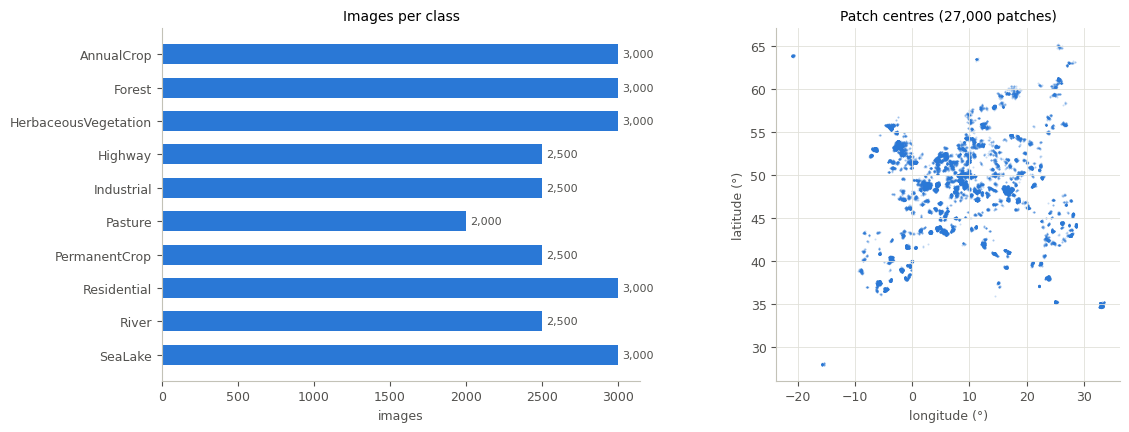

images per class: 2,000 to 3,000 (1.5x imbalance)
distance to the nearest other patch centre: median 0.79 km; 59 % of the patches have a neighbour within 1 km (a patch is 0.64 km wide)


In [8]:
def to_xyz(lon, lat, radius=6371.0):
    """Points on a sphere (km), so that Euclidean distances approximate great-circle distances."""
    lon, lat = np.deg2rad(lon), np.deg2rad(lat)
    return radius * np.stack([np.cos(lat) * np.cos(lon), np.cos(lat) * np.sin(lon), np.sin(lat)], axis=1)


counts = meta.class_name.value_counts().reindex(CLASSES)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1, 1.4]})
ax1.barh(CLASSES[::-1], counts.values[::-1], color=BLUE, height=0.6)
for i, v in enumerate(counts.values[::-1]):
    ax1.text(v + counts.max() * 0.01, i, f"{v:,}", va="center", fontsize=8, color=INK2)
ax1.set_xlabel("images")
ax1.set_title("Images per class")
ax2.scatter(meta.lon, meta.lat, s=2, color=BLUE, alpha=0.25, linewidths=0)
ax2.set_aspect(1 / np.cos(np.deg2rad(meta.lat.mean())))
ax2.grid(True)
ax2.set_xlabel("longitude (°)")
ax2.set_ylabel("latitude (°)")
ax2.set_title(f"Patch centres ({len(meta):,} patches)")
plt.tight_layout()
save("dataset_overview")

xyz = to_xyz(meta.lon.values, meta.lat.values)
nn_dist = cKDTree(xyz).query(xyz, k=2)[0][:, 1]
print(f"images per class: {counts.min():,} to {counts.max():,} ({counts.max() / counts.min():.1f}x imbalance)")
print(f"distance to the nearest other patch centre: median {np.median(nn_dist):.2f} km; {(nn_dist < 1).mean() * 100:.0f} % "
      f"of the patches have a neighbour within 1 km (a patch is 0.64 km wide)")

Mild class imbalance; the patches are spatially clustered (relevant for section 12).

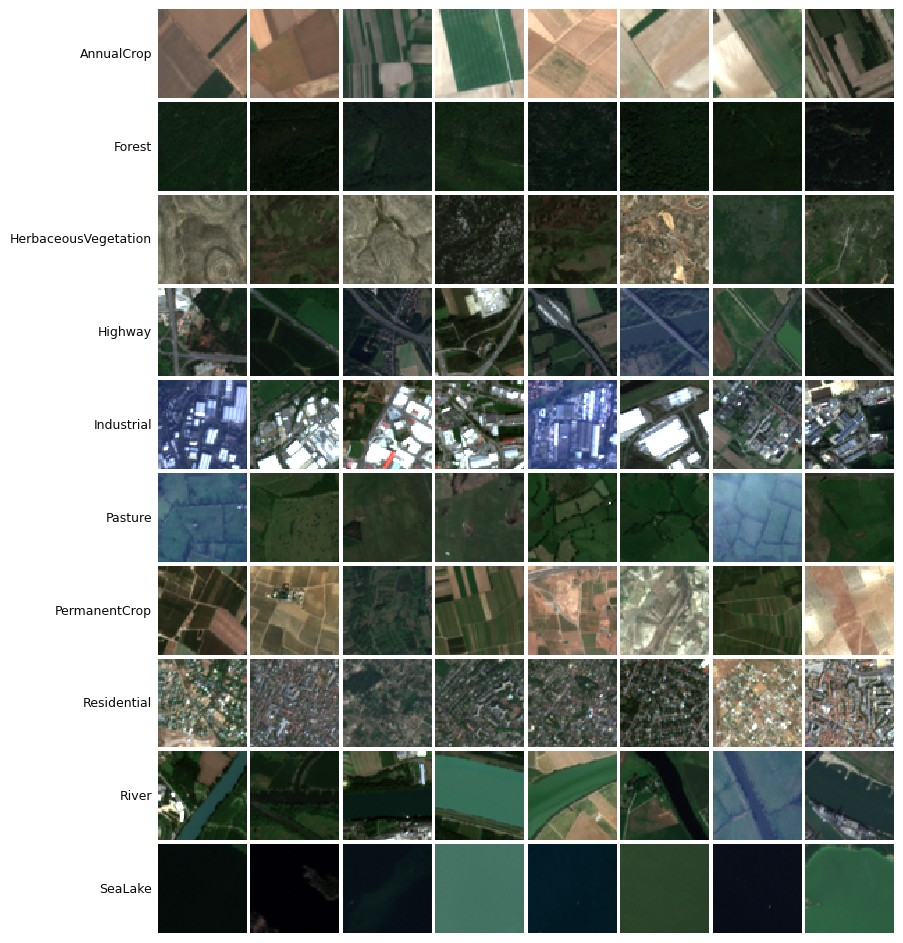

In [9]:
rng = np.random.default_rng(SEED)
display_sample = x_all[rng.choice(SPLITS["random"]["train"], 500, replace=False)].astype(np.float32)
LO, HI = np.percentile(display_sample, [1, 99], axis=(0, 2, 3))


def composite(img, bands=RGB):
    """Three bands of a reflectance image (bands x H x W) as an RGB image, with a fixed linear stretch per band."""
    x = np.asarray(img, dtype=np.float32)[bands]
    lo, hi = LO[bands, None, None], HI[bands, None, None]
    return ((x - lo) / (hi - lo)).clip(0, 1).transpose(1, 2, 0)


fig, axes = plt.subplots(NUM_CLASSES, 8, figsize=(9.5, 12))
for c, row in enumerate(axes):
    for ax, i in zip(row, rng.choice(np.flatnonzero(y_all == c), 8, replace=False)):
        ax.imshow(composite(x_all[i]))
        no_axes(ax)
    row[0].set_ylabel(CLASSES[c], rotation=0, ha="right", va="center", fontsize=9, color=INK)
plt.subplots_adjust(wspace=0.04, hspace=0.04)
save("samples", photo=True)

All 13 bands of one patch:

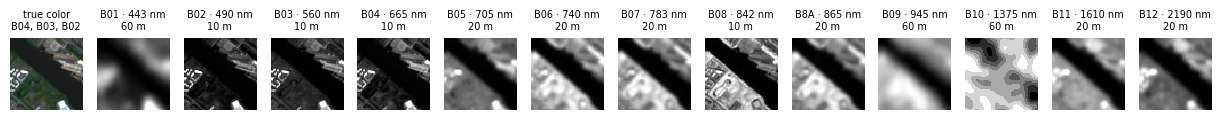

In [10]:
i = rng.choice(np.flatnonzero(y_all == CLASSES.index("River")))
fig, axes = plt.subplots(1, 14, figsize=(15.5, 1.9))
axes[0].imshow(composite(x_all[i]))
axes[0].set_title("true color\nB04, B03, B02", fontsize=7)
for ax, b in zip(axes[1:], BY_WAVELENGTH):
    band = x_all[i, b].astype(np.float32)
    ax.imshow(band, cmap="gray", vmin=np.percentile(band, 1), vmax=np.percentile(band, 99))
    ax.set_title(f"{BANDS.band[b]} · {WAVELENGTH[b]} nm\n{BANDS['native resolution (m)'][b]} m", fontsize=7)
for ax in axes:
    no_axes(ax)
save("bands")

The 60 m bands (B01, B09, B10) are blurred; water is dark in the NIR and SWIR.

**Composites and spectral indices** (vegetation appears red in color infrared):
- **NDVI** = (B08 − B04) / (B08 + B04): vegetation
- **NDWI** = (B03 − B08) / (B03 + B08): water
- **NDBI** = (B11 − B08) / (B11 + B08): built-up areas

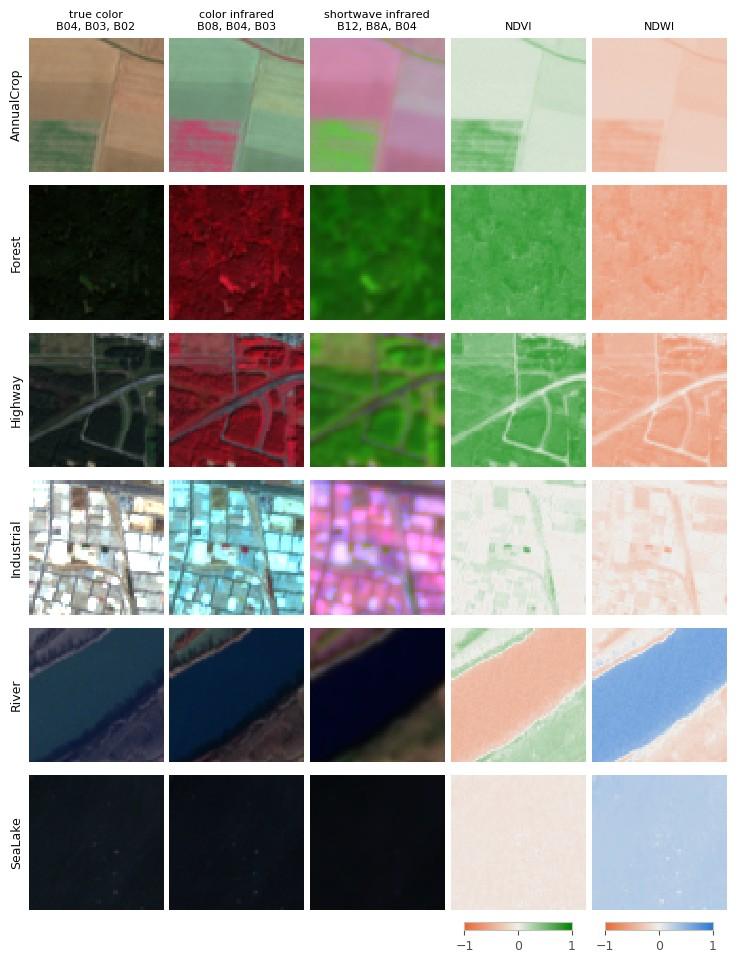

In [11]:
INDICES = {"NDVI": ("B08", "B04"), "NDWI": ("B03", "B08"), "NDBI": ("B11", "B08")}


def norm_diff(x, a, b):
    """Normalized difference (a - b) / (a + b) of two bands; x has the bands on axis -3."""
    a, b = x[..., B[a], :, :].astype(np.float32), x[..., B[b], :, :].astype(np.float32)
    return (a - b) / (a + b + 1e-6)


views = [("true color\nB04, B03, B02", RGB), ("color infrared\nB08, B04, B03", [B["B08"], B["B04"], B["B03"]]),
         ("shortwave infrared\nB12, B8A, B04", [B["B12"], B["B8A"], B["B04"]])]
show = ["AnnualCrop", "Forest", "Highway", "Industrial", "River", "SeaLake"]
fig, axes = plt.subplots(len(show) + 1, 5, figsize=(9, 11.6), gridspec_kw={"height_ratios": [1] * len(show) + [0.06]})
for r, cname in enumerate(show):
    i = rng.choice(np.flatnonzero(y_all == CLASSES.index(cname)))
    for c, (_, bands) in enumerate(views):
        axes[r, c].imshow(composite(x_all[i], bands))
    im_ndvi = axes[r, 3].imshow(norm_diff(x_all[i], *INDICES["NDVI"]), cmap=NDVI_CMAP, vmin=-1, vmax=1)
    im_ndwi = axes[r, 4].imshow(norm_diff(x_all[i], *INDICES["NDWI"]), cmap=NDWI_CMAP, vmin=-1, vmax=1)
    for ax in axes[r]:
        no_axes(ax)
    axes[r, 0].set_ylabel(cname, fontsize=9, color=INK)
for c, title in enumerate([v[0] for v in views] + ["NDVI", "NDWI"]):
    axes[0, c].set_title(title, fontsize=8)
for ax in axes[-1, :3]:
    ax.axis("off")
plt.subplots_adjust(wspace=0.05, hspace=0.1)
for cax, im in ((axes[-1, 3], im_ndvi), (axes[-1, 4], im_ndwi)):
    pos = cax.get_position()
    cax.set_position([pos.x0 + 0.1 * pos.width, pos.y0, 0.8 * pos.width, pos.height])
    fig.colorbar(im, cax=cax, orientation="horizontal", ticks=[-1, 0, 1])
save("composites", photo=True)

**Spectral signatures** (median and interquartile range per class):

per-image statistics (27000, 32) in 13 s


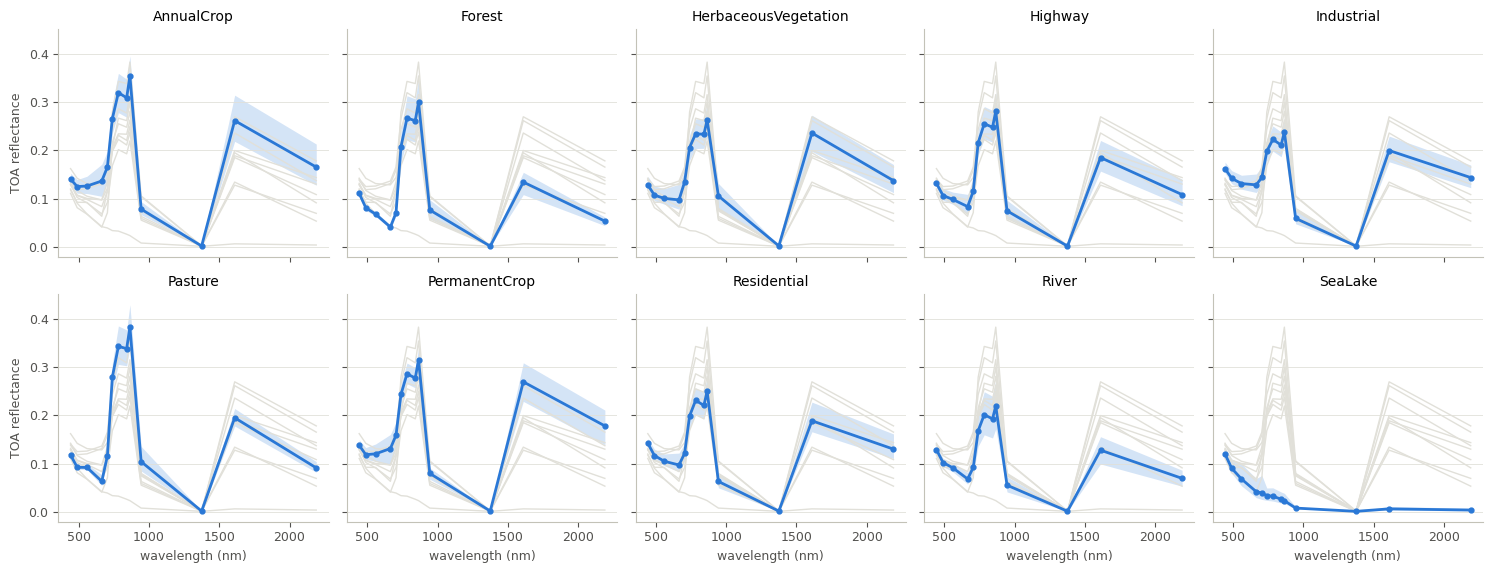

In [12]:
def image_statistics(x, chunk=1000):
    """Per-image mean and standard deviation of every band and of the three spectral indices."""
    out = []
    for i in range(0, len(x), chunk):
        xc = x[i:i + chunk].astype(np.float32)
        idx = np.stack([norm_diff(xc, a, b) for a, b in INDICES.values()], axis=1)
        out.append(np.concatenate([xc.mean((2, 3)), xc.std((2, 3)), idx.mean((2, 3)), idx.std((2, 3))], axis=1))
    columns = ([f"mean_{b}" for b in BANDS.band] + [f"std_{b}" for b in BANDS.band]
               + [f"mean_{k}" for k in INDICES] + [f"std_{k}" for k in INDICES])
    return pd.DataFrame(np.concatenate(out), columns=columns)


t0 = time.time()
img_stats = image_statistics(x_all)
print(f"per-image statistics {img_stats.shape} in {time.time() - t0:.0f} s")

spectra = img_stats[[f"mean_{BANDS.band[b]}" for b in BY_WAVELENGTH]].values
wl = WAVELENGTH[BY_WAVELENGTH]
median = np.stack([np.median(spectra[y_all == c], 0) for c in range(NUM_CLASSES)])
q25, q75 = (np.stack([np.percentile(spectra[y_all == c], q, 0) for c in range(NUM_CLASSES)]) for q in (25, 75))

fig, axes = plt.subplots(2, 5, figsize=(15, 5.8), sharex=True, sharey=True)
for c, ax in enumerate(axes.flat):
    for o in range(NUM_CLASSES):
        if o != c:
            ax.plot(wl, median[o], color=LIGHT_GRAY, lw=1)
    ax.fill_between(wl, q25[c], q75[c], color=BLUE, alpha=0.2, lw=0)
    ax.plot(wl, median[c], color=BLUE, lw=2, marker="o", ms=3.5)
    ax.set_title(CLASSES[c])
    ax.grid(True, axis="y")
for ax in axes[1]:
    ax.set_xlabel("wavelength (nm)")
for ax in axes[:, 0]:
    ax.set_ylabel("TOA reflectance")
plt.tight_layout()
save("spectral_signatures")

Vegetation shows the red edge and a high NIR plateau; water is near zero beyond 900 nm.

Mean NDVI, NDWI and NDBI per patch:

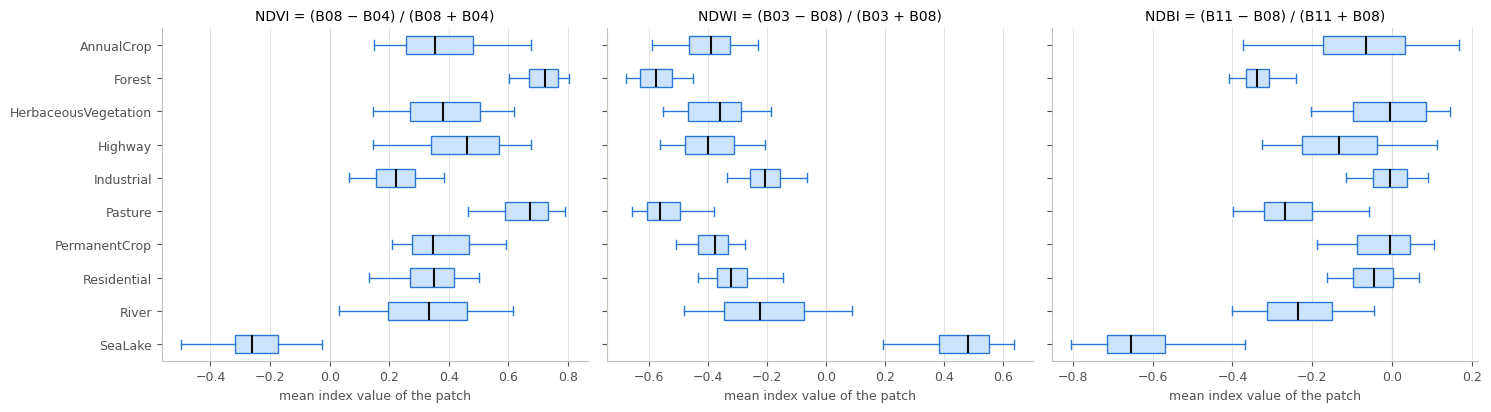

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for k, (ax, name) in enumerate(zip(axes, INDICES)):
    data = [img_stats.loc[y_all == c, f"mean_{name}"].values for c in range(NUM_CLASSES)]
    ax.boxplot(data, vert=False, whis=(5, 95), showfliers=False, widths=0.55, patch_artist=True,
               boxprops=dict(facecolor="#cde2fb", edgecolor=BLUE), whiskerprops=dict(color=BLUE),
               capprops=dict(color=BLUE), medianprops=dict(color=INK, lw=1.5))
    ax.axvline(0, color=GRAY, lw=0.8, zorder=0)
    ax.set_yticks(range(1, NUM_CLASSES + 1), CLASSES)
    ax.tick_params(labelleft=k == 0)
    ax.invert_yaxis()
    a, b = INDICES[name]
    ax.set_title(f"{name} = ({a} − {b}) / ({a} + {b})")
    ax.set_xlabel("mean index value of the patch")
    ax.grid(True, axis="x")
plt.tight_layout()
save("spectral_indices")

NDVI and NDWI separate vegetation and water well; NDBI does not isolate built-up areas, and no single index separates all classes.

**Band redundancy:** correlation and PCA.

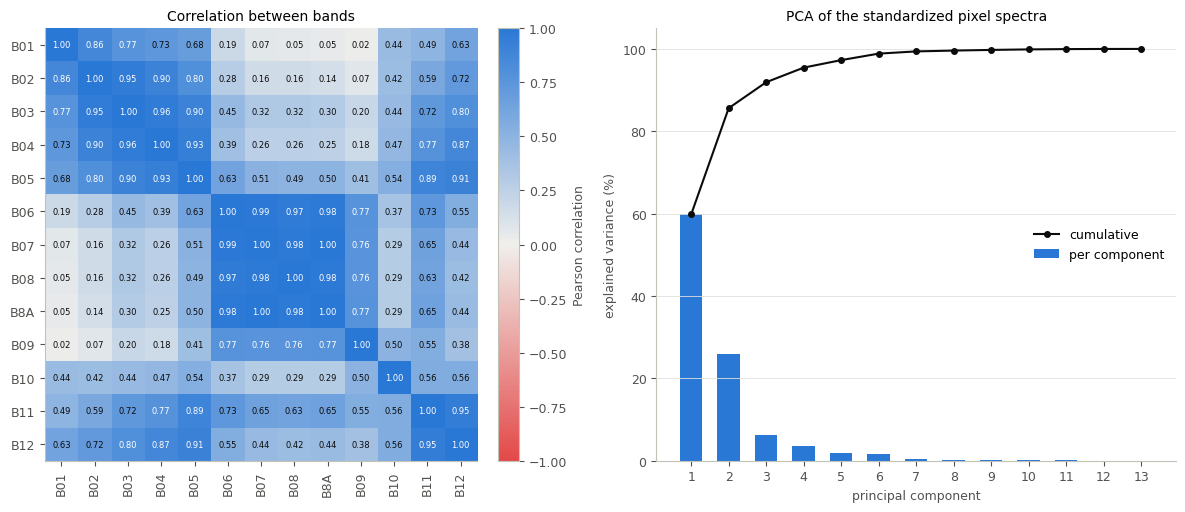

cumulative explained variance of the first 5 components (%): [59.8 85.6 91.9 95.5 97.3]


In [14]:
pix = x_all[rng.choice(len(x_all), 300, replace=False)].astype(np.float32)
pix = pix.transpose(1, 0, 2, 3).reshape(len(BANDS), -1)[BY_WAVELENGTH]       # bands x pixels
corr = np.corrcoef(pix)
pca = PCA().fit(((pix.T - pix.mean(1)) / pix.std(1)))
cum = np.cumsum(pca.explained_variance_ratio_) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.2), gridspec_kw={"width_ratios": [1.3, 1]})
im = ax1.imshow(corr, cmap=DIV, vmin=-1, vmax=1)
names = [BANDS.band[b] for b in BY_WAVELENGTH]
ax1.set_xticks(range(len(names)), names, rotation=90)
ax1.set_yticks(range(len(names)), names)
for r in range(len(names)):
    for c in range(len(names)):
        ax1.text(c, r, f"{corr[r, c]:.2f}", ha="center", va="center", fontsize=6,
                 color="white" if abs(corr[r, c]) > 0.75 else INK)
fig.colorbar(im, ax=ax1, fraction=0.046, pad=0.03, label="Pearson correlation")
ax1.set_title("Correlation between bands")
ax2.bar(range(1, len(cum) + 1), pca.explained_variance_ratio_ * 100, color=BLUE, width=0.6, label="per component")
ax2.plot(range(1, len(cum) + 1), cum, color=INK, marker="o", ms=4, lw=1.5, label="cumulative")
ax2.set_xticks(range(1, len(cum) + 1))
ax2.set_xlabel("principal component")
ax2.set_ylabel("explained variance (%)")
ax2.grid(True, axis="y")
ax2.legend(loc="center right")
ax2.set_title("PCA of the standardized pixel spectra")
plt.tight_layout()
save("band_correlation")
print("cumulative explained variance of the first 5 components (%):", cum[:5].round(1))

Two highly correlated band groups, (B02–B05, B11, B12) and (B06, B07, B08, B8A); four principal components explain 95 % of the variance. All 13 bands are kept.

## 4. Preprocessing

- Per-band standardization with **training-set** statistics only (no leakage).
- Data stay in memory as float16; batches are augmented and standardized on the GPU.
- Native 64 × 64 size, no upsampling.

In [15]:
def band_stats(idx, chunk=500):
    """Per-band mean and standard deviation over all pixels of the images in idx."""
    s, s2, n = np.zeros(len(BANDS)), np.zeros(len(BANDS)), 0
    for i in range(0, len(idx), chunk):
        x = x_all[idx[i:i + chunk]].astype(np.float64)
        s += x.sum((0, 2, 3))
        s2 += (x ** 2).sum((0, 2, 3))
        n += x.shape[0] * x.shape[2] * x.shape[3]
    mean = s / n
    return mean, np.sqrt(s2 / n - mean ** 2)


NORM = {p: band_stats(SPLITS[p]["train"]) for p in SPLITS}
pd.DataFrame({"mean (random split)": NORM["random"][0], "std (random split)": NORM["random"][1],
              "mean (spatial split)": NORM["spatial"][0], "std (spatial split)": NORM["spatial"][1]},
             index=BANDS.band).T.round(4)

band,B01,B02,B03,B04,B05,B06,B07,B08,B09,B10,B11,B12,B8A
mean (random split),0.1354,0.1118,0.1043,0.0948,0.1199,0.2000,0.2369,0.2297,0.0732,0.0012,0.1819,0.1119,0.2594
std (random split),0.0245,0.0331,0.0393,0.0591,0.0565,0.0860,0.1085,0.1116,0.0405,0.0005,0.1002,0.0760,0.1230
mean (spatial split),0.1376,0.1143,0.1077,0.1004,0.1281,0.2130,0.2524,0.2454,0.0785,0.0012,0.1970,0.1206,0.2779
std (spatial split),0.0250,0.0336,0.0390,0.0610,0.0561,0.0806,0.1022,0.1064,0.0411,0.0005,0.0957,0.0739,0.1156


In [16]:
X = torch.from_numpy(x_all)              # float16 reflectance in CPU memory (shares memory with x_all)
Y = torch.from_numpy(y_all).long()


def batches(idx, batch_size=BATCH_SIZE, shuffle=False):
    """Mini-batches (reflectance as float32 on the GPU, labels) of the images in idx."""
    idx = torch.as_tensor(idx)
    if shuffle:
        idx = idx[torch.randperm(len(idx))]
    for i in range(0, len(idx), batch_size):
        j = idx[i:i + batch_size]
        yield X[j].to(device, non_blocking=True).float(), Y[j].to(device, non_blocking=True)


class Standardize:
    """Selects the input bands and standardizes them with the training statistics of a split protocol."""

    def __init__(self, protocol, bands):
        mean, std = NORM[protocol]
        self.bands = torch.tensor(bands, device=device)
        self.mean = torch.tensor(mean[bands], dtype=torch.float32, device=device).view(1, -1, 1, 1)
        self.std = torch.tensor(std[bands], dtype=torch.float32, device=device).view(1, -1, 1, 1)

    def __call__(self, x):
        return (x.index_select(1, self.bands) - self.mean) / self.std


xb, yb = next(batches(SPLITS["random"]["train"], shuffle=True))
z = Standardize("random", ALL_BANDS)(xb)
print(f"standardized batch {tuple(z.shape)} on {z.device}: mean {z.mean():.3f}, std {z.std():.3f}")

standardized batch (128, 13, 64, 64) on cuda:0: mean -0.025, std 0.981


## 5. Data augmentation

- **D4 group** (8 rotations/flips): a top-down image has no "up", so the label is unchanged.
- **Radiometric jitter** on reflectance: global and per-band gain, Gaussian noise.

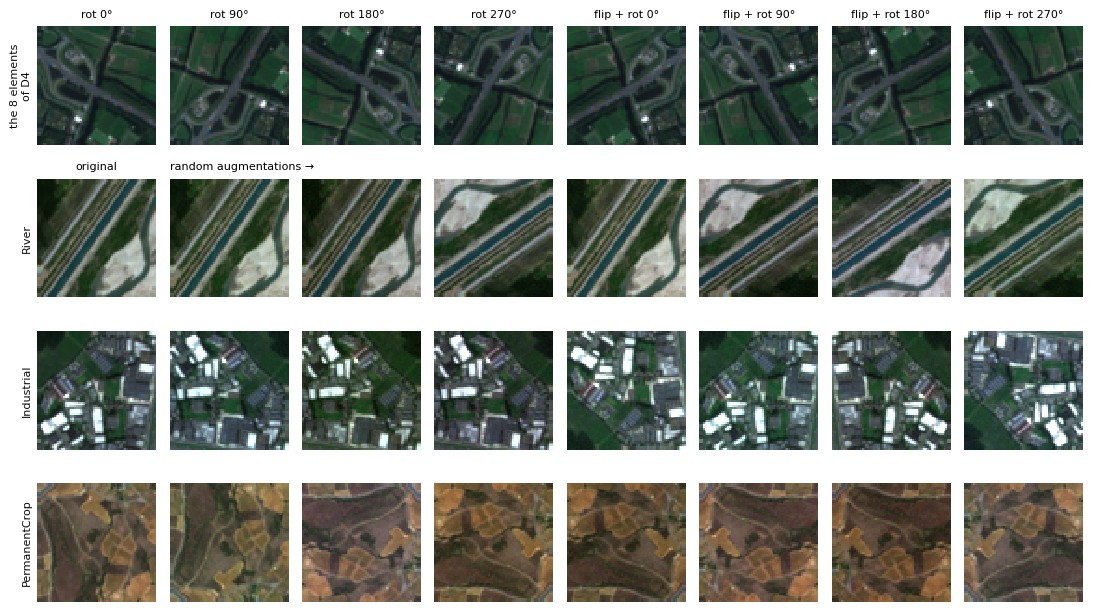

In [17]:
def augment(x):
    """Random D4 symmetry and radiometric jitter for a batch of reflectances (B, bands, H, W) on the GPU."""
    b, c = x.shape[:2]
    gain = torch.empty(b, 1, 1, 1, device=x.device).uniform_(0.9, 1.1)           # illumination, atmosphere
    band_gain = torch.empty(b, c, 1, 1, device=x.device).uniform_(0.97, 1.03)    # band-specific effects
    x = x * gain * band_gain + 0.002 * torch.randn_like(x)                       # + sensor noise
    x = torch.where(torch.rand(b, 1, 1, 1, device=x.device) < 0.5, x.flip(-1), x)
    k = torch.randint(0, 4, (b,), device=x.device)                               # rotation by k * 90 degrees
    out = x.clone()
    for r in (1, 2, 3):
        out[k == r] = torch.rot90(x[k == r], r, dims=(-2, -1))
    return out


torch.manual_seed(SEED)
train_idx = SPLITS["random"]["train"]
pick = lambda name: int(rng.choice(train_idx[y_all[train_idx] == CLASSES.index(name)]))
d4_example = X[pick("Highway")].float().to(device)
rows = ["River", "Industrial", "PermanentCrop"]
examples = X[torch.tensor([pick(n) for n in rows])].float().to(device)

fig, axes = plt.subplots(4, 8, figsize=(11, 6.3))
for j in range(8):
    v = torch.rot90(d4_example.flip(-1) if j >= 4 else d4_example, j % 4, dims=(-2, -1))
    axes[0, j].imshow(composite(v.cpu().numpy()))
    axes[0, j].set_title(("flip + " if j >= 4 else "") + f"rot {90 * (j % 4)}°", fontsize=8)
for r in range(3):
    axes[r + 1, 0].imshow(composite(examples[r].cpu().numpy()))
    for j in range(1, 8):
        axes[r + 1, j].imshow(composite(augment(examples[r:r + 1])[0].cpu().numpy()))
for ax in axes.flat:
    no_axes(ax)
axes[0, 0].set_ylabel("the 8 elements\nof D4", fontsize=8, color=INK)
for r, name in enumerate(rows):
    axes[r + 1, 0].set_ylabel(name, fontsize=8, color=INK)
axes[1, 0].set_title("original", fontsize=8)
axes[1, 1].set_title("random augmentations →", fontsize=8, loc="left")
plt.tight_layout()
save("augmentation", photo=True)

## 6. Classical baseline: hand-crafted features

42 features per patch: band mean/std (26), NDVI/NDWI/NDBI mean/std (6) and Haralick GLCM texture of the 10 m bands (10). Classifiers, tuned on validation: Gaussian maximum likelihood (QDA), random forest and RBF-SVM.

In [18]:
TEN_M = [B["B02"], B["B03"], B["B04"], B["B08"]]
GLCM_PROPS = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation"]
GLCM_DIST, GLCM_ANGLES, LEVELS = [1, 3], [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4], 32
GRAY_RANGE = (0.03, 0.30)


def glcm_features(x):
    feats = np.empty((len(x), len(GLCM_PROPS) * len(GLCM_DIST)), dtype=np.float32)
    for i, img in enumerate(x):
        gray = img[TEN_M].astype(np.float32).mean(0)
        q = ((gray - GRAY_RANGE[0]) / (GRAY_RANGE[1] - GRAY_RANGE[0])).clip(0, 0.999) * LEVELS
        P = graycomatrix(q.astype(np.uint8), GLCM_DIST, GLCM_ANGLES, levels=LEVELS, symmetric=True, normed=True)
        feats[i] = np.concatenate([graycoprops(P, p).mean(1) for p in GLCM_PROPS])
    return feats


gray_sample = display_sample[:, TEN_M].mean(1)
inside = ((gray_sample >= GRAY_RANGE[0]) & (gray_sample <= GRAY_RANGE[1])).mean() * 100
t0 = time.time()
texture = pd.DataFrame(glcm_features(x_all), columns=[f"{p}_d{d}" for p in GLCM_PROPS for d in GLCM_DIST])
features = pd.concat([img_stats, texture], axis=1)
F_all = features.values
GROUPS = {"spectral statistics": list(img_stats.columns[:2 * len(BANDS)]),
          "spectral indices": list(img_stats.columns[2 * len(BANDS):]),
          "GLCM texture": list(texture.columns)}
print(f"{inside:.1f} % of the pixels lie inside the quantization range")
print(f"{features.shape[1]} features per image ({', '.join(f'{k}: {len(v)}' for k, v in GROUPS.items())}); "
      f"texture computed in {time.time() - t0:.0f} s")

99.5 % of the pixels lie inside the quantization range
42 features per image (spectral statistics: 26, spectral indices: 6, GLCM texture: 10); texture computed in 14 s


Evaluation helpers:

In [19]:
def bootstrap_ci(correct, n=2000, seed=SEED):
    """95 % bootstrap confidence interval of the accuracy (resampling the test images)."""
    r = np.random.default_rng(seed)
    acc = [correct[r.integers(0, len(correct), len(correct))].mean() for _ in range(n)]
    return np.percentile(acc, [2.5, 97.5])


def scores(y_true, y_pred):
    correct = y_pred == y_true
    lo, hi = bootstrap_ci(correct)
    return {"OA (%)": 100 * correct.mean(), "95% CI": f"{100 * lo:.2f} to {100 * hi:.2f}",
            "macro-F1 (%)": 100 * f1_score(y_true, y_pred, average="macro", zero_division=0),
            "kappa": cohen_kappa_score(y_true, y_pred)}


tr, va, te = (SPLITS["random"][s] for s in ("train", "val", "test"))
CANDIDATES = {
    "Gaussian ML (QDA)": {f"reg = {r}": make_pipeline(StandardScaler(), QuadraticDiscriminantAnalysis(reg_param=r))
                          for r in (1e-4, 1e-3, 1e-2, 1e-1)},
    "Random forest": {"500 trees": RandomForestClassifier(500, n_jobs=-1, random_state=SEED)},
    "RBF-SVM": {f"C = {C}": make_pipeline(StandardScaler(), SVC(C=C, gamma="scale")) for C in (1, 10, 100)},
}
classical, rows = {}, []
for name, options in CANDIDATES.items():
    fitted = []
    for setting, clf in options.items():
        t0 = time.time()
        clf.fit(F_all[tr], y_all[tr])
        seconds = time.time() - t0
        fitted.append(((clf.predict(F_all[va]) == y_all[va]).mean(), setting, clf, seconds))
        print(f"{name:18s} {setting:12s} val OA {100 * fitted[-1][0]:.2f} %  ({seconds:.1f} s)")
    val_acc, setting, clf, seconds = max(fitted, key=lambda f: f[0])
    classical[name] = clf
    rows.append({"model": name, "selected setting": setting, "val OA (%)": 100 * val_acc, "fit time (s)": seconds})
classical_results = pd.DataFrame(rows).set_index("model")
classical_results.round(2)

Gaussian ML (QDA)  reg = 0.0001 val OA 90.83 %  (0.0 s)
Gaussian ML (QDA)  reg = 0.001  val OA 90.20 %  (0.0 s)
Gaussian ML (QDA)  reg = 0.01   val OA 88.19 %  (0.0 s)


Gaussian ML (QDA)  reg = 0.1    val OA 86.65 %  (0.0 s)


Random forest      500 trees    val OA 92.48 %  (5.0 s)


RBF-SVM            C = 1        val OA 92.54 %  (0.9 s)


RBF-SVM            C = 10       val OA 94.89 %  (0.7 s)


RBF-SVM            C = 100      val OA 95.46 %  (0.8 s)


,selected setting,val OA (%),fit time (s)
model,,,
Gaussian ML (QDA),reg = 0.0001,90.83,0.04
Random forest,500 trees,92.48,5.05
RBF-SVM,C = 100,95.46,0.81


**Feature-group ablation** (random forest, validation OA):

In [20]:
band_cols = lambda bands: [f"{s}_{b}" for s in ("mean", "std") for b in bands]
feature_sets = {
    "RGB bands only (B02-B04)": band_cols(["B02", "B03", "B04"]),
    "all 13 bands": GROUPS["spectral statistics"],
    "all 13 bands + spectral indices": GROUPS["spectral statistics"] + GROUPS["spectral indices"],
    "GLCM texture only": GROUPS["GLCM texture"],
    "all 42 features": list(features.columns),
}
rows = []
for name, cols in feature_sets.items():
    Fs = features[cols].values
    rf = RandomForestClassifier(500, n_jobs=-1, random_state=SEED).fit(Fs[tr], y_all[tr])
    rows.append({"features": name, "dimension": len(cols), "val OA (%)": 100 * (rf.predict(Fs[va]) == y_all[va]).mean()})
feature_ablation = pd.DataFrame(rows).set_index("features")
feature_ablation.to_csv(RESULTS_DIR / "feature_groups.csv")
feature_ablation.round(2)

,dimension,val OA (%)
features,,
RGB bands only (B02-B04),6,75.91
all 13 bands,26,88.54
all 13 bands + spectral indices,32,90.41
GLCM texture only,10,71.98
all 42 features,42,92.48


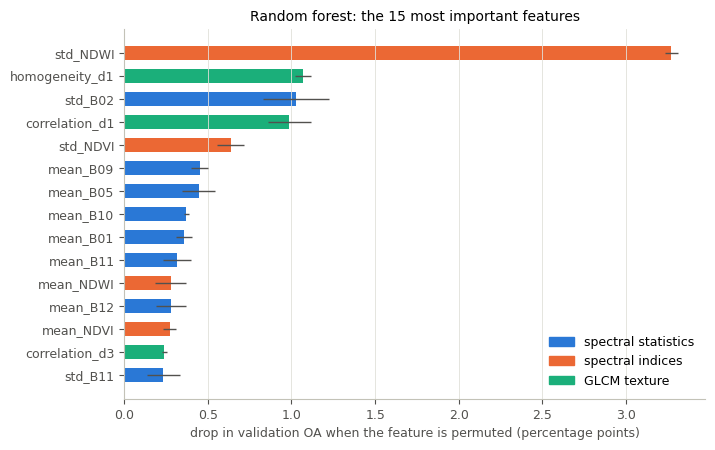

In [21]:
imp = permutation_importance(classical["Random forest"], F_all[va], y_all[va], n_repeats=3, random_state=SEED)
top = np.argsort(imp.importances_mean)[::-1][:15]
group_of = {c: g for g, cols in GROUPS.items() for c in cols}
group_color = dict(zip(GROUPS, [BLUE, ORANGE, AQUA]))

fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.barh(range(len(top)), 100 * imp.importances_mean[top], xerr=100 * imp.importances_std[top], height=0.6,
        color=[group_color[group_of[features.columns[i]]] for i in top], error_kw=dict(ecolor=INK2, lw=1))
ax.set_yticks(range(len(top)), features.columns[top])
ax.invert_yaxis()
ax.set_xlabel("drop in validation OA when the feature is permuted (percentage points)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in group_color.values()], labels=list(group_color),
          loc="lower right")
ax.grid(True, axis="x")
ax.set_title("Random forest: the 15 most important features")
save("classical_importance")

- Best classical model: **RBF-SVM** (95.46 % validation OA).
- The spectral bands matter most (RGB 75.9 % → 13 bands 88.5 %); indices and texture add 4 points.
- The atmospheric bands (B01, B09, B10) rank high: a possible shortcut under the random split.

## 7. CNN architectures

- **SpectralSpatialCNN** (0.59 M parameters, from scratch): a 1 × 1 convolution mixes the bands, followed by 3 × 3 convolution stages.
- **ResNet-18** with ImageNet weights: the first layer is inflated to 13 bands (RGB filters for B04/B03/B02, their mean for the others, scaled by 3/13); max-pooling is removed for the 64 px input.

In [22]:
def conv_bn(c_in, c_out, k=3):
    return nn.Sequential(nn.Conv2d(c_in, c_out, k, padding=k // 2, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True))


class SpectralSpatialCNN(nn.Module):
    """1x1 spectral mixing, then a small VGG-style stack of 3x3 convolutions."""

    def __init__(self, in_bands, num_classes=NUM_CLASSES):
        super().__init__()
        self.spectral = conv_bn(in_bands, 32, k=1)                                        # per-pixel band mixing
        self.stage1 = nn.Sequential(conv_bn(32, 32), nn.MaxPool2d(2))                      # 64 -> 32 px
        self.stage2 = nn.Sequential(conv_bn(32, 64), conv_bn(64, 64), nn.MaxPool2d(2))     # 32 -> 16 px
        self.stage3 = nn.Sequential(conv_bn(64, 128), conv_bn(128, 128), nn.MaxPool2d(2))  # 16 -> 8 px
        self.stage4 = conv_bn(128, 256)
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(256, num_classes))

    def forward_features(self, x):
        x = self.stage4(self.stage3(self.stage2(self.stage1(self.spectral(x)))))
        return x.mean((2, 3))                                                             # global average pooling

    def forward(self, x):
        return self.head(self.forward_features(x))


def inflate_first_conv(conv, rgb_pos, in_bands):
    """Multispectral version of a pretrained RGB convolution: the R, G, B filters go to the input bands at
    rgb_pos, every other band starts from the mean RGB filter, and all weights are scaled by 3 / in_bands."""
    w = conv.weight.detach()                                                              # (64, 3, 7, 7)
    new_w = w.mean(1, keepdim=True).repeat(1, in_bands, 1, 1)
    new_w[:, rgb_pos] = w
    new = nn.Conv2d(in_bands, conv.out_channels, conv.kernel_size, conv.stride, conv.padding, bias=False)
    new.weight.data.copy_(new_w * 3 / in_bands)
    return new


class ResNet18MS(nn.Module):
    """ResNet-18 for 64 x 64 px multispectral patches."""

    def __init__(self, bands, pretrained=True, num_classes=NUM_CLASSES):
        super().__init__()
        net = torchvision.models.resnet18(weights="IMAGENET1K_V1" if pretrained else None)
        if pretrained:
            net.conv1 = inflate_first_conv(net.conv1, [bands.index(b) for b in RGB], len(bands))
        else:
            net.conv1 = nn.Conv2d(len(bands), 64, 7, 2, 3, bias=False)
            nn.init.kaiming_normal_(net.conv1.weight, mode="fan_out", nonlinearity="relu")
        net.maxpool = nn.Identity()       # 64 px input -> 4 x 4 maps after layer4 instead of 2 x 2
        net.fc = nn.Identity()
        self.backbone = net
        self.head = nn.Linear(512, num_classes)

    def forward_features(self, x):
        return self.backbone(x)

    def forward(self, x):
        return self.head(self.forward_features(x))


def summary(model, parts, in_bands):
    rows, hooks = [], []
    for name, module in parts:
        hooks.append(module.register_forward_hook(lambda m, i, o, name=name: rows.append(
            (name, tuple(o.shape[1:]), sum(p.numel() for p in m.parameters())))))
    model.eval()
    with torch.no_grad():
        model(torch.zeros(2, in_bands, 64, 64))
    for h in hooks:
        h.remove()
    print(pd.DataFrame(rows, columns=["block", "output shape", "parameters"]).to_string(index=False))
    print(f"total: {sum(p.numel() for p in model.parameters()):,} parameters\n")


cnn = SpectralSpatialCNN(len(ALL_BANDS))
print("SpectralSpatialCNN")
summary(cnn, [("spectral (1x1 conv)", cnn.spectral), ("stage 1", cnn.stage1), ("stage 2", cnn.stage2),
              ("stage 3", cnn.stage3), ("stage 4", cnn.stage4), ("classifier", cnn.head)], len(ALL_BANDS))
r18 = ResNet18MS(ALL_BANDS)
print("ResNet-18, 13 bands")
summary(r18, [("conv1 (inflated)", r18.backbone.conv1)]
        + [(f"layer{i}", getattr(r18.backbone, f"layer{i}")) for i in range(1, 5)] + [("classifier", r18.head)],
        len(ALL_BANDS))

SpectralSpatialCNN
              block output shape  parameters
spectral (1x1 conv) (32, 64, 64)         480
            stage 1 (32, 32, 32)        9280
            stage 2 (64, 16, 16)       55552
            stage 3  (128, 8, 8)      221696
            stage 4  (256, 8, 8)      295424
         classifier        (10,)        2570
total: 585,002 parameters

ResNet-18, 13 bands
           block  output shape  parameters
conv1 (inflated)  (64, 32, 32)       40768
          layer1  (64, 32, 32)      147968
          layer2 (128, 16, 16)      525568
          layer3   (256, 8, 8)     2099712
          layer4   (512, 4, 4)     8393728
      classifier         (10,)        5130
total: 11,213,002 parameters



Check: with only B04, B03, B02 non-zero, the output must be 3/13 of the original layer's.

In [23]:
rgb_layer = torchvision.models.resnet18(weights="IMAGENET1K_V1").conv1
x_test = torch.zeros(1, len(ALL_BANDS), 64, 64)
x_test[:, RGB] = torch.randn(1, 3, 64, 64)
with torch.no_grad():
    diff = (r18.backbone.conv1(x_test) - rgb_layer(x_test[:, RGB]) * 3 / len(ALL_BANDS)).abs().max().item()
print(f"max. difference: {diff:.2e}")

max. difference: 1.19e-06


## 8. Training

AdamW, one-cycle schedule, label smoothing 0.1, 20 epochs, mixed precision; the best validation epoch is kept. Each run changes one factor:

| run | architecture | input bands | initialization | augmentation |
|---|---|---|---|---|
| **R18-MS** (main model) | ResNet-18 | all 13 | ImageNet | yes |
| R18-RGB | ResNet-18 | B04, B03, B02 | ImageNet | yes |
| R18-MS-scratch | ResNet-18 | all 13 | random | yes |
| R18-MS-noaug | ResNet-18 | all 13 | ImageNet | no |
| CNN-MS | SpectralSpatialCNN | all 13 | random | yes |

In [24]:
criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)


@torch.no_grad()
def predict(model, idx, norm, features=False, tta=False, batch_size=512):
    """Logits (or penultimate features) for the images in idx; tta: mean softmax over the 8 D4 views."""
    model.eval()
    out = []
    for xb, _ in batches(idx, batch_size):
        xb = norm(xb)
        with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
            if features:
                o = model.forward_features(xb)
            elif tta:
                o = torch.stack([model(torch.rot90(v, k, (-2, -1))).float().softmax(1)
                                 for v in (xb, xb.flip(-1)) for k in range(4)]).mean(0)
            else:
                o = model(xb)
        out.append(o.float())
    return torch.cat(out)


def train(model, bands, protocol="random", augmentation=True, epochs=EPOCHS, lr=LR):
    seed_everything(SEED)
    norm = Standardize(protocol, bands)
    tr_idx, va_idx = SPLITS[protocol]["train"], SPLITS[protocol]["val"]
    y_va = Y[va_idx].to(device)
    model = model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=lr, epochs=epochs, pct_start=0.2,
                                                    steps_per_epoch=math.ceil(len(tr_idx) / BATCH_SIZE))
    scaler = torch.amp.GradScaler(device.type, enabled=use_amp)
    history, best_acc, t_start = [], -1.0, time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        loss_sum, correct = torch.zeros((), device=device), torch.zeros((), device=device)
        for xb, yb in batches(tr_idx, shuffle=True):
            if augmentation:
                xb = augment(xb)
            with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
                logits = model(norm(xb))
                loss = criterion(logits, yb)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            loss_sum += loss.detach() * len(yb)
            correct += (logits.argmax(1) == yb).sum()
        val_logits = predict(model, va_idx, norm)
        val_acc = (val_logits.argmax(1) == y_va).float().mean().item()
        history.append({"epoch": epoch, "train_loss": loss_sum.item() / len(tr_idx), "train_acc": correct.item() / len(tr_idx),
                        "val_loss": criterion(val_logits, y_va).item(), "val_acc": val_acc})
        if val_acc > best_acc:
            best_acc, best_epoch = val_acc, epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if epoch % 5 == 0 or epoch == epochs:
            h = history[-1]
            print(f"  epoch {epoch:2d}: train loss {h['train_loss']:.3f}, val loss {h['val_loss']:.3f}, val OA {100 * val_acc:.2f} %")
    model.load_state_dict(best_state)
    minutes = (time.time() - t_start) / 60
    print(f"  -> {minutes:.1f} min, best val OA {100 * best_acc:.2f} % (epoch {best_epoch})")
    return model, pd.DataFrame(history), minutes

In [25]:
RUNS = {   # name: (model constructor, input bands, augmentation)
    "R18-MS": (lambda: ResNet18MS(ALL_BANDS), ALL_BANDS, True),
    "R18-RGB": (lambda: ResNet18MS(RGB), RGB, True),
    "R18-MS-scratch": (lambda: ResNet18MS(ALL_BANDS, pretrained=False), ALL_BANDS, True),
    "R18-MS-noaug": (lambda: ResNet18MS(ALL_BANDS), ALL_BANDS, False),
    "CNN-MS": (lambda: SpectralSpatialCNN(len(ALL_BANDS)), ALL_BANDS, True),
}
models, histories, minutes, RUN_BANDS = {}, {}, {}, {}
for name, (make_model, bands, aug) in RUNS.items():
    print(name)
    seed_everything(SEED)
    models[name], histories[name], minutes[name] = train(make_model(), bands, augmentation=aug)
    RUN_BANDS[name] = bands
    torch.save(models[name].state_dict(), CKPT_DIR / f"{name}.pt")
pd.concat(histories, names=["run"]).to_csv(RESULTS_DIR / "training_history.csv")

R18-MS


  epoch  5: train loss 0.610, val loss 0.633, val OA 94.37 %


  epoch 10: train loss 0.554, val loss 0.566, val OA 97.52 %


  epoch 15: train loss 0.524, val loss 0.538, val OA 98.43 %


  epoch 20: train loss 0.510, val loss 0.526, val OA 98.93 %
  -> 3.6 min, best val OA 99.04 % (epoch 18)
R18-RGB


  epoch  5: train loss 0.619, val loss 0.660, val OA 93.57 %


... (11 outputs left out)

  epoch  5: train loss 0.722, val loss 0.889, val OA 83.72 %


  epoch 10: train loss 0.642, val loss 0.654, val OA 94.13 %


  epoch 15: train loss 0.595, val loss 0.629, val OA 95.07 %


  epoch 20: train loss 0.575, val loss 0.610, val OA 96.13 %
  -> 2.0 min, best val OA 96.24 % (epoch 19)


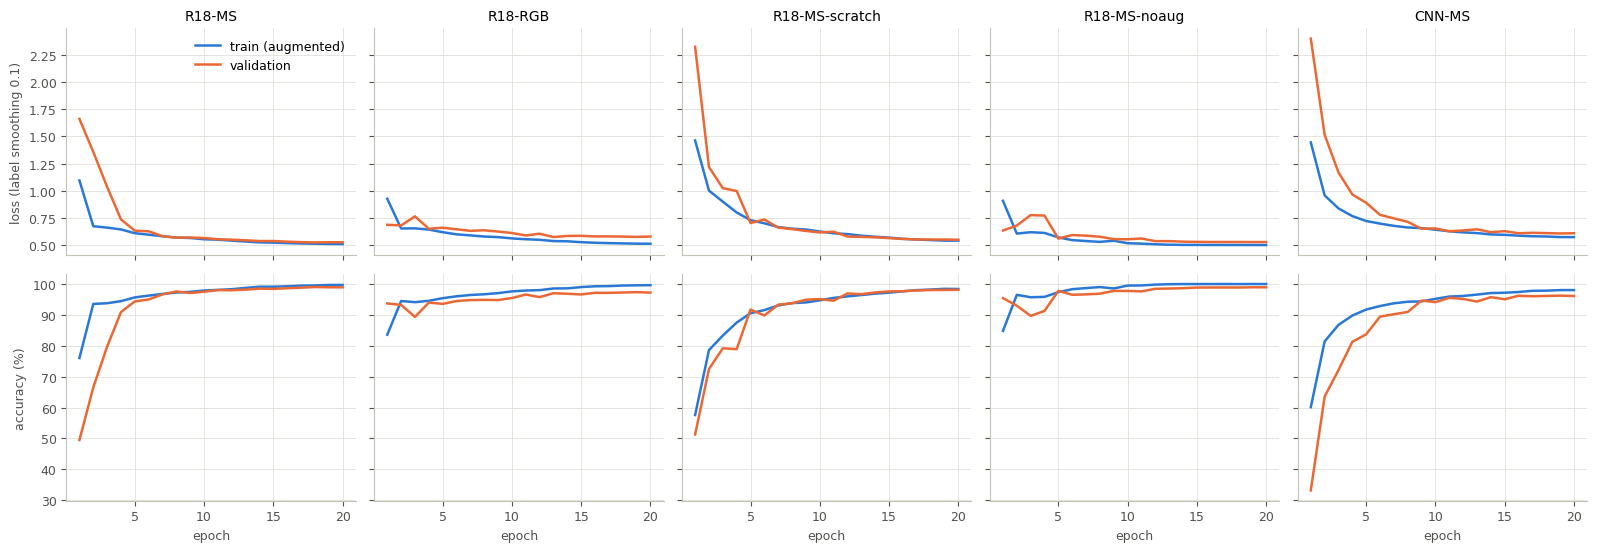

,best epoch,best val OA (%),training time (min)
R18-MS,18.0,99.04,3.64
R18-RGB,19.0,97.37,3.28
R18-MS-scratch,20.0,98.13,3.43
R18-MS-noaug,19.0,98.94,3.25
CNN-MS,19.0,96.24,1.99


In [26]:
fig, axes = plt.subplots(2, len(RUNS), figsize=(16, 5.6), sharex=True, sharey="row")
for j, name in enumerate(RUNS):
    h = histories[name]
    axes[0, j].plot(h.epoch, h.train_loss, color=BLUE, lw=1.8, label="train (augmented)" if RUNS[name][2] else "train")
    axes[0, j].plot(h.epoch, h.val_loss, color=ORANGE, lw=1.8, label="validation")
    axes[1, j].plot(h.epoch, 100 * h.train_acc, color=BLUE, lw=1.8)
    axes[1, j].plot(h.epoch, 100 * h.val_acc, color=ORANGE, lw=1.8)
    axes[0, j].set_title(name)
    axes[1, j].set_xlabel("epoch")
    for ax in axes[:, j]:
        ax.grid(True)
axes[0, 0].set_ylabel("loss (label smoothing 0.1)")
axes[1, 0].set_ylabel("accuracy (%)")
axes[0, 0].legend()
plt.tight_layout()
save("training_curves")

pd.DataFrame({name: {"best epoch": int(h.val_acc.idxmax()) + 1, "best val OA (%)": 100 * h.val_acc.max(),
                     "training time (min)": minutes[name]} for name, h in histories.items()}).T.round(2)

All runs converge without strong overfitting; ImageNet initialization mainly speeds up training.

## 9. Test evaluation

OA with 95 % bootstrap CI, macro-F1 and Cohen's κ. **McNemar's test** with Holm correction checks whether two models differ significantly. TTA averages the predictions over the 8 D4 views.

In [27]:
y_te = y_all[te]
pred = {name: clf.predict(F_all[te]) for name, clf in classical.items()}
for name in RUNS:
    pred[name] = predict(models[name], te, Standardize("random", RUN_BANDS[name])).argmax(1).cpu().numpy()
pred["R18-MS + TTA"] = predict(models["R18-MS"], te, Standardize("random", ALL_BANDS), tta=True).argmax(1).cpu().numpy()
best_classical = classical_results["val OA (%)"].idxmax()

rows = []
for name, p in pred.items():
    base = name.replace(" + TTA", "")
    is_cnn = base in models
    rows.append({"model": name, **scores(y_te, p),
                 "parameters (M)": sum(q.numel() for q in models[base].parameters()) / 1e6 if is_cnn else np.nan,
                 "training time (min)": minutes[base] if is_cnn else classical_results.loc[base, "fit time (s)"] / 60})
test_results = pd.DataFrame(rows).set_index("model")
test_results.to_csv(RESULTS_DIR / "test_metrics.csv")
test_results.round({"OA (%)": 2, "macro-F1 (%)": 2, "kappa": 4, "parameters (M)": 2, "training time (min)": 2})

,OA (%),95% CI,macro-F1 (%),kappa,parameters (M),training time (min)
model,,,,,,
Gaussian ML (QDA),90.83,90.09 to 91.59,90.19,0.8980,NaN,0.00
Random forest,92.43,91.74 to 93.11,92.03,0.9157,NaN,0.08
RBF-SVM,95.31,94.74 to 95.87,95.05,0.9479,NaN,0.01
R18-MS,98.70,98.39 to 99.00,98.67,0.9856,11.21,3.64
R18-RGB,97.74,97.33 to 98.11,97.77,0.9749,11.18,3.28
R18-MS-scratch,97.91,97.50 to 98.28,97.85,0.9767,11.21,3.43
R18-MS-noaug,98.57,98.26 to 98.89,98.53,0.9841,11.21,3.25
CNN-MS,95.93,95.37 to 96.44,95.78,0.9547,0.59,1.99
R18-MS + TTA,98.80,98.50 to 99.07,98.76,0.9866,11.21,3.64


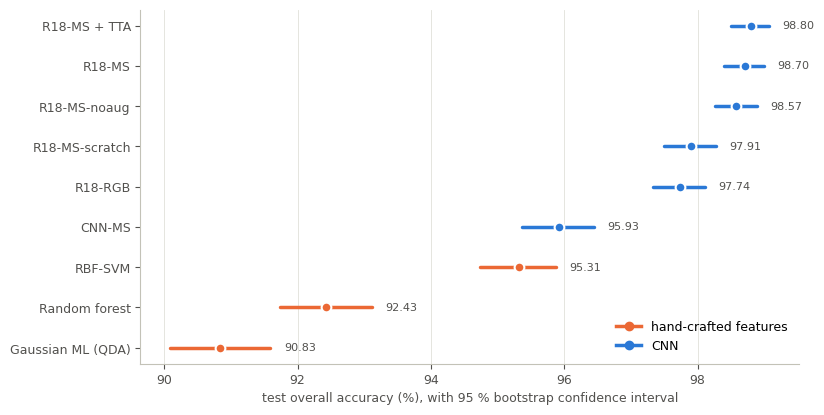

In [28]:
order = test_results.sort_values("OA (%)").index
fig, ax = plt.subplots(figsize=(8.5, 4.6))
for i, name in enumerate(order):
    correct = pred[name] == y_te
    lo, hi = 100 * bootstrap_ci(correct)
    color = ORANGE if name in classical else BLUE
    ax.plot([lo, hi], [i, i], color=color, lw=2.5, solid_capstyle="round")
    ax.plot(100 * correct.mean(), i, "o", color=color, ms=7, markeredgecolor="white", markeredgewidth=1.5)
    ax.text(hi + 0.2, i, f"{100 * correct.mean():.2f}", va="center", fontsize=8, color=INK2)
ax.set_yticks(range(len(order)), order)
ax.set_xlabel("test overall accuracy (%), with 95 % bootstrap confidence interval")
ax.grid(True, axis="x")
ax.legend(handles=[plt.Line2D([], [], color=ORANGE, marker="o", lw=2.5, label="hand-crafted features"),
                   plt.Line2D([], [], color=BLUE, marker="o", lw=2.5, label="CNN")], loc="lower right")
save("test_accuracy")

Confusion matrices (diagonal: recall in %, off-diagonal: counts):

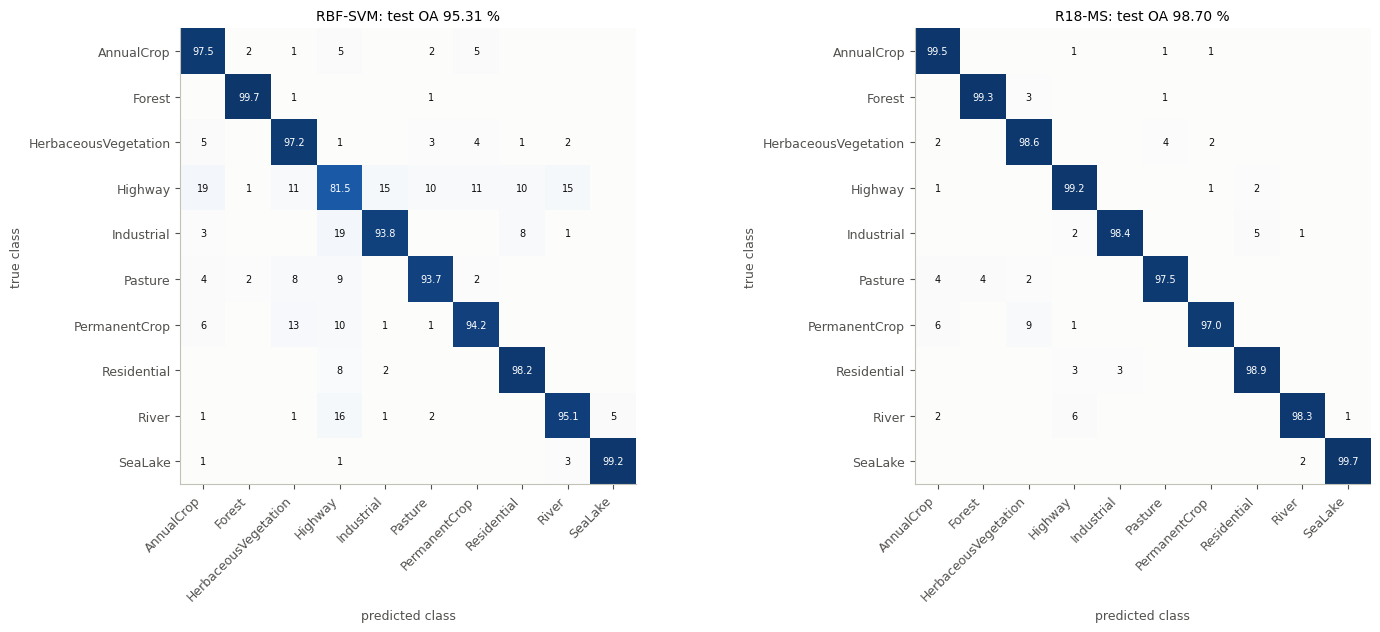

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.4))
for ax, name in zip(axes, [best_classical, "R18-MS"]):
    cm = confusion_matrix(y_te, pred[name], labels=range(NUM_CLASSES))
    cm_pct = 100 * cm / cm.sum(1, keepdims=True)
    ax.imshow(cm_pct, cmap=SEQ, vmin=0, vmax=100)
    for r in range(NUM_CLASSES):
        for c in range(NUM_CLASSES):
            if cm[r, c]:
                ax.text(c, r, f"{cm_pct[r, c]:.1f}" if r == c else str(cm[r, c]), ha="center", va="center",
                        fontsize=7, color="white" if cm_pct[r, c] > 50 else INK)
    ax.set_xticks(range(NUM_CLASSES), CLASSES, rotation=45, ha="right")
    ax.set_yticks(range(NUM_CLASSES), CLASSES)
    ax.set_xlabel("predicted class")
    ax.set_ylabel("true class")
    ax.set_title(f"{name}: test OA {100 * (pred[name] == y_te).mean():.2f} %")
plt.tight_layout()
save("confusion_matrices")

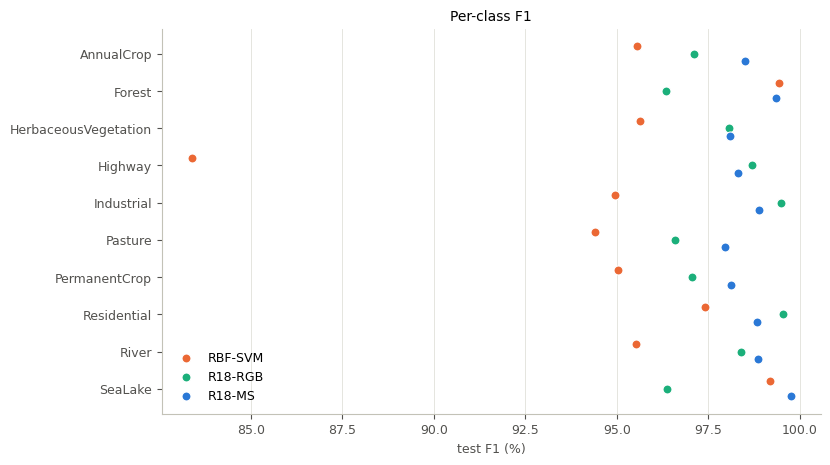

,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River,SeaLake
RBF-SVM,95.56,99.43,95.62,83.38,94.95,94.40,95.03,97.40,95.54,99.18
R18-RGB,97.11,96.34,98.08,98.69,99.50,96.60,97.06,99.55,98.39,96.36
R18-MS,98.50,99.34,98.09,98.30,98.90,97.97,98.12,98.83,98.86,99.75


In [30]:
compare = {best_classical: ORANGE, "R18-RGB": AQUA, "R18-MS": BLUE}
f1_classes = pd.DataFrame({n: 100 * f1_score(y_te, pred[n], average=None, labels=range(NUM_CLASSES), zero_division=0)
                           for n in compare}, index=CLASSES)
fig, ax = plt.subplots(figsize=(8.5, 5))
for k, (name, color) in enumerate(compare.items()):
    ax.scatter(f1_classes[name], np.arange(NUM_CLASSES) + (k - 1) * 0.2, color=color, s=42, label=name, zorder=3,
               edgecolors="white", linewidths=0.8)
ax.set_yticks(range(NUM_CLASSES), CLASSES)
ax.invert_yaxis()
ax.set_xlabel("test F1 (%)")
ax.grid(True, axis="x")
ax.legend(loc="lower left")
ax.set_title("Per-class F1")
save("per_class_f1")
f1_classes.to_csv(RESULTS_DIR / "per_class_f1.csv")
f1_classes.round(2).T

In [31]:
def mcnemar(pred_a, pred_b, y):
    """Exact McNemar test on the images where exactly one of the two classifiers is correct."""
    a, b = pred_a == y, pred_b == y
    only_a, only_b = int((a & ~b).sum()), int((~a & b).sum())
    p = stats.binomtest(only_a, only_a + only_b, 0.5).pvalue if only_a + only_b else 1.0
    return only_a, only_b, p


def holm(p):
    """Holm-Bonferroni adjusted p-values."""
    p = np.asarray(p, dtype=float)
    order = np.argsort(p)
    adjusted = np.minimum(np.maximum.accumulate((len(p) - np.arange(len(p))) * p[order]), 1)
    out = np.empty_like(adjusted)
    out[order] = adjusted
    return out


COMPARISONS = [("R18-MS", "R18-RGB", "13 bands vs. RGB"),
               ("R18-MS", "R18-MS-scratch", "ImageNet vs. random initialization"),
               ("R18-MS", "R18-MS-noaug", "augmentation vs. none"),
               ("R18-MS", "CNN-MS", "ResNet-18 vs. compact CNN"),
               ("R18-MS", best_classical, "CNN vs. best hand-crafted pipeline"),
               ("R18-MS + TTA", "R18-MS", "test-time augmentation vs. none")]
mc = pd.DataFrame([(q, a, b, *mcnemar(pred[a], pred[b], y_te)) for a, b, q in COMPARISONS],
                  columns=["question", "A", "B", "only A correct", "only B correct", "p"])
mc["p (Holm)"] = holm(mc.p)
mc["significant at 5 %"] = np.where(mc["p (Holm)"] < 0.05, "yes", "no")
mc.to_csv(RESULTS_DIR / "mcnemar.csv", index=False)
mc.assign(p=mc.p.map("{:.2g}".format), **{"p (Holm)": mc["p (Holm)"].map("{:.2g}".format)})

,question,A,B,only A correct,only B correct,p,p (Holm),significant at 5 %
0,13 bands vs. RGB,R18-MS,R18-RGB,95,43,1.1e-05,4.5e-05,yes
1,ImageNet vs. random initialization,R18-MS,R18-MS-scratch,72,29,2.2e-05,6.7e-05,yes
2,augmentation vs. none,R18-MS,R18-MS-noaug,40,33,0.48,0.66,no
3,ResNet-18 vs. compact CNN,R18-MS,CNN-MS,174,24,2.9e-29,1.4e-28,yes
4,CNN vs. best hand-crafted pipeline,R18-MS,RBF-SVM,211,28,6.5e-36,3.9e-35,yes
5,test-time augmentation vs. none,R18-MS + TTA,R18-MS,11,6,0.33,0.66,no


- **13 bands vs. RGB:** 70 vs. 122 errors (p < 10⁻⁴); RGB confuses dark forest with water, which the NIR separates.
- **CNN vs. SVM:** 98.70 % vs. 95.31 %; the largest gap is Highway (recall 99.2 % vs. 81.5 %).
- ImageNet initialization helps (+0.79 points, significant); augmentation and TTA are not significant.

## 10. What did the network learn?

**Band importance:** accuracy drop when one band is shuffled across the test images.

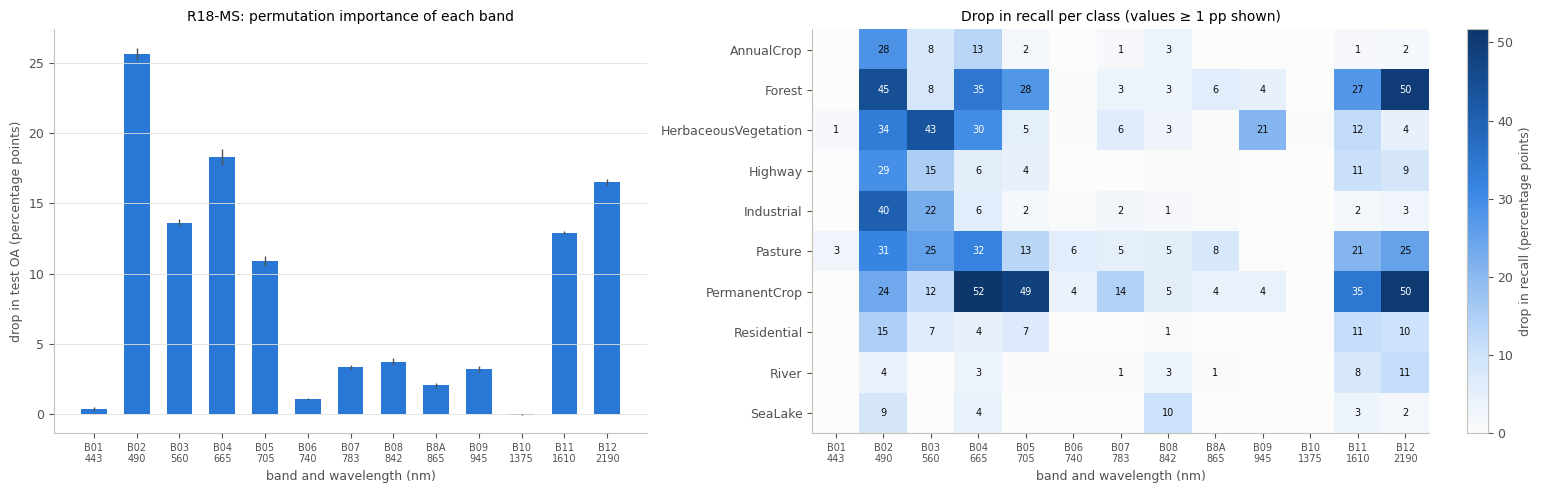

In [32]:
@torch.no_grad()
def predict_permuted_band(model, idx, norm, band, perm, batch_size=512):
    model.eval()
    out = []
    for s in range(0, len(idx), batch_size):
        xb = X[torch.as_tensor(idx[s:s + batch_size])].to(device).float()
        xb[:, band] = X[torch.as_tensor(idx[perm[s:s + batch_size]]), band].to(device).float()
        with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
            out.append(model(norm(xb)).argmax(1))
    return torch.cat(out).cpu().numpy()


def recall_per_class(y, p):
    return np.array([(p[y == c] == c).mean() for c in range(NUM_CLASSES)])


main_norm = Standardize("random", ALL_BANDS)
base_oa, base_recall = (pred["R18-MS"] == y_te).mean(), recall_per_class(y_te, pred["R18-MS"])
perm_rng = np.random.default_rng(SEED)
drops, class_drops = np.zeros((len(BANDS), 3)), np.zeros((len(BANDS), NUM_CLASSES))
for b in ALL_BANDS:
    for r in range(3):
        p = predict_permuted_band(models["R18-MS"], te, main_norm, b, perm_rng.permutation(len(te)))
        drops[b, r] = 100 * (base_oa - (p == y_te).mean())
        class_drops[b] += 100 * (base_recall - recall_per_class(y_te, p)) / 3
pd.DataFrame({"band": BANDS.band, "wavelength (nm)": WAVELENGTH, "OA drop (pp)": drops.mean(1),
              "std (pp)": drops.std(1)}).to_csv(RESULTS_DIR / "band_importance.csv", index=False)

labels = [f"{BANDS.band[b]}\n{WAVELENGTH[b]}" for b in BY_WAVELENGTH]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 1.3]})
ax1.bar(range(len(BANDS)), drops.mean(1)[BY_WAVELENGTH], yerr=drops.std(1)[BY_WAVELENGTH], color=BLUE, width=0.6,
        error_kw=dict(ecolor=INK2, lw=1))
ax1.set_xticks(range(len(BANDS)), labels, fontsize=7)
ax1.set_xlabel("band and wavelength (nm)")
ax1.set_ylabel("drop in test OA (percentage points)")
ax1.set_title("R18-MS: permutation importance of each band")
ax1.grid(True, axis="y")
heat = class_drops[BY_WAVELENGTH].T
im = ax2.imshow(heat, cmap=SEQ, vmin=0, aspect="auto")
for r in range(NUM_CLASSES):
    for c in range(len(BANDS)):
        if heat[r, c] >= 1:
            ax2.text(c, r, f"{heat[r, c]:.0f}", ha="center", va="center", fontsize=7,
                     color="white" if heat[r, c] > 0.55 * heat.max() else INK)
ax2.set_xticks(range(len(BANDS)), labels, fontsize=7)
ax2.set_yticks(range(NUM_CLASSES), CLASSES)
ax2.set_xlabel("band and wavelength (nm)")
fig.colorbar(im, ax=ax2, label="drop in recall (percentage points)")
ax2.set_title("Drop in recall per class (values ≥ 1 pp shown)")
plt.tight_layout()
save("band_importance")

- Most important: the visible (B02), SWIR (B12) and red-edge (B05) bands.
- The NIR bands look unimportant only because they are nearly identical (r ≥ 0.97).

### Grad-CAM

On `layer3`, two random test images per class:

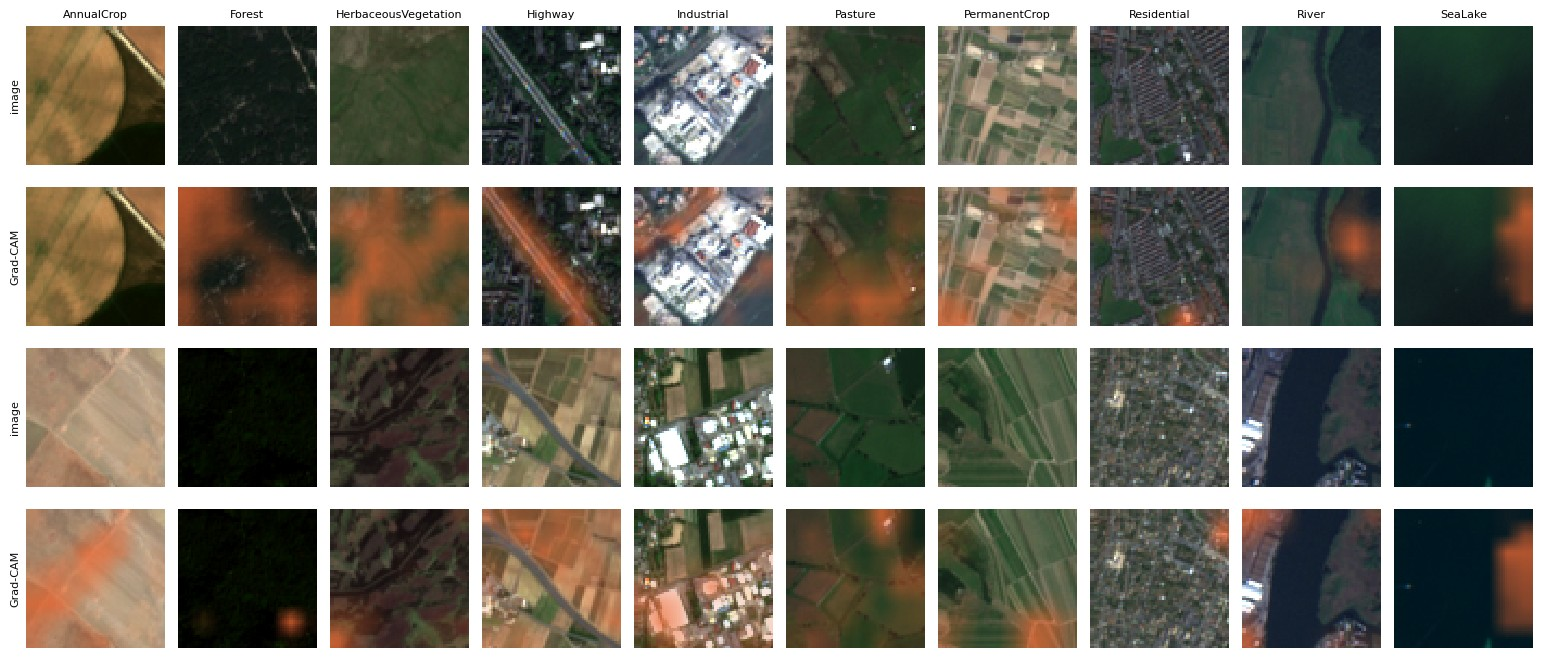

In [33]:
def grad_cam(model, x, layer):
    """Grad-CAM maps (B, H, W) in [0, 1] for the predicted class of every image of the standardized batch x."""
    store = {}

    def hook(module, inputs, output):
        store["act"] = output
        output.register_hook(lambda g: store.__setitem__("grad", g))

    handle = layer.register_forward_hook(hook)
    model.eval()
    logits = model(x)
    cls = logits.argmax(1)
    model.zero_grad()
    logits.gather(1, cls[:, None]).sum().backward()
    handle.remove()
    model.zero_grad(set_to_none=True)
    weights = store["grad"].mean((2, 3), keepdim=True)
    cam = F.relu((weights * store["act"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
    return (cam / cam.amax((1, 2), keepdim=True).clamp_min(1e-8)).detach().cpu().numpy(), cls.cpu().numpy()


def overlay(rgb, cam, color=ORANGE):
    alpha = 0.75 * cam[..., None]
    return rgb * (1 - alpha) + np.array(to_rgb(color)) * alpha


cam_rng = np.random.default_rng(SEED)
chosen = np.concatenate([cam_rng.choice(np.flatnonzero(y_te == c), 2, replace=False) for c in range(NUM_CLASSES)])
xb = X[torch.as_tensor(te[chosen])].to(device).float()
cams, cam_pred = grad_cam(models["R18-MS"], main_norm(xb), models["R18-MS"].backbone.layer3)

fig, axes = plt.subplots(4, NUM_CLASSES, figsize=(15.5, 6.8))
for k in range(len(chosen)):
    r, c = 2 * (k % 2), k // 2
    rgb = composite(xb[k].cpu().numpy())
    axes[r, c].imshow(rgb)
    axes[r + 1, c].imshow(overlay(rgb, cams[k]))
    ok = cam_pred[k] == y_te[chosen[k]]
    axes[r + 1, c].set_title("" if ok else f"predicted: {CLASSES[cam_pred[k]]}", fontsize=7, color=BAD)
for c in range(NUM_CLASSES):
    axes[0, c].set_title(CLASSES[c], fontsize=8)
for ax in axes.flat:
    no_axes(ax)
for r, label in enumerate(["image", "Grad-CAM", "image", "Grad-CAM"]):
    axes[r, 0].set_ylabel(label, fontsize=8, color=INK)
plt.tight_layout()
save("gradcam", photo=True)

The maps follow roads and riverbanks; for homogeneous classes they are diffuse.

### t-SNE

Hand-crafted vs. CNN features:

t-SNE in 21 s


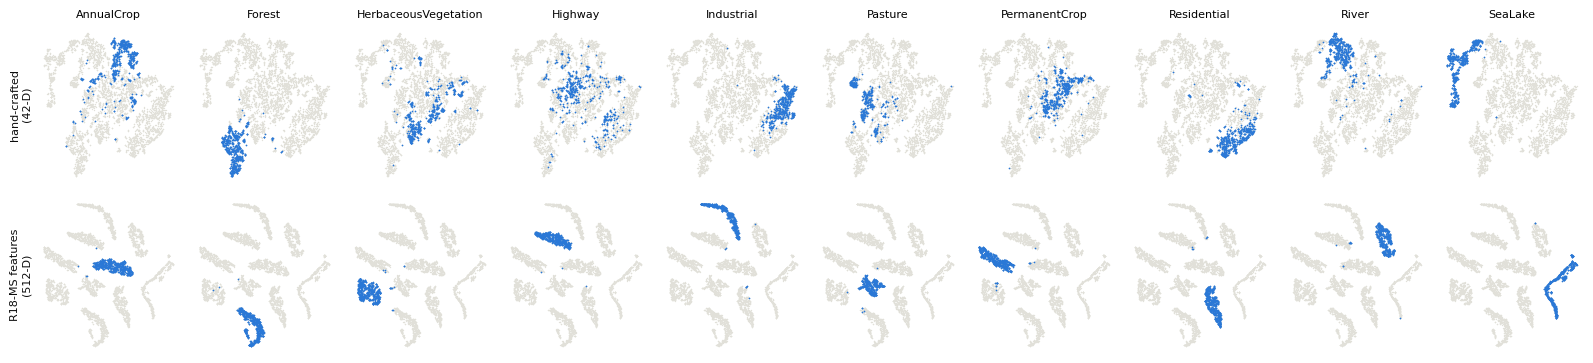

In [34]:
def tsne_2d(e):
    e = PCA(n_components=min(50, e.shape[1]), random_state=SEED).fit_transform(e)
    return TSNE(n_components=2, init="pca", perplexity=30, random_state=SEED, n_jobs=-1).fit_transform(e)


feature_scaler = StandardScaler().fit(F_all[tr])
emb_hand = feature_scaler.transform(F_all[te])
emb_cnn = predict(models["R18-MS"], te, main_norm, features=True).cpu().numpy()
t0 = time.time()
maps = {"hand-crafted\n(42-D)": tsne_2d(emb_hand), "R18-MS features\n(512-D)": tsne_2d(emb_cnn)}
print(f"t-SNE in {time.time() - t0:.0f} s")

fig, axes = plt.subplots(2, NUM_CLASSES, figsize=(16, 3.7))
for r, (title, m) in enumerate(maps.items()):
    for c in range(NUM_CLASSES):
        ax = axes[r, c]
        ax.scatter(m[:, 0], m[:, 1], s=1, color=LIGHT_GRAY, linewidths=0, rasterized=True)
        ax.scatter(m[y_te == c, 0], m[y_te == c, 1], s=1.5, color=BLUE, linewidths=0, rasterized=True)
        no_axes(ax)
        if r == 0:
            ax.set_title(CLASSES[c], fontsize=8)
    axes[r, 0].set_ylabel(title, fontsize=8, color=INK)
plt.tight_layout()
save("tsne")

### Errors

R18-MS: 70 errors on 5,400 test images. Most frequent confusions (true -> predicted):
PermanentCrop -> HerbaceousVegetation    9
PermanentCrop -> AnnualCrop              6
River -> Highway                         6
Industrial -> Residential                5
Pasture -> AnnualCrop                    4
Pasture -> Forest                        4
HerbaceousVegetation -> Pasture          4
Residential -> Highway                   3


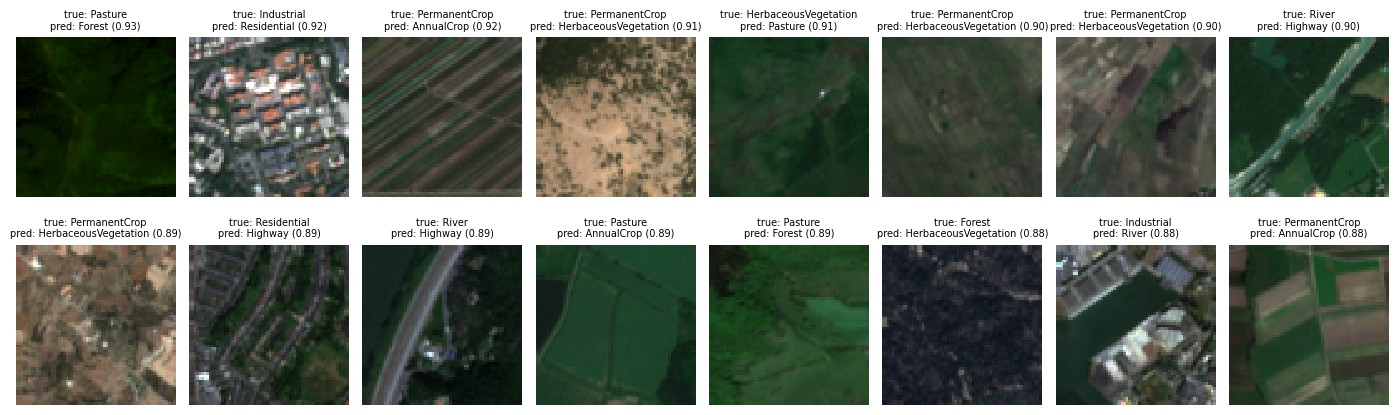

In [35]:
prob_te = predict(models["R18-MS"], te, main_norm).softmax(1).cpu().numpy()
wrong = np.flatnonzero(pred["R18-MS"] != y_te)
pairs = pd.Series([f"{CLASSES[y_te[i]]} -> {CLASSES[pred['R18-MS'][i]]}" for i in wrong]).value_counts()
print(f"R18-MS: {len(wrong)} errors on {len(te):,} test images. Most frequent confusions (true -> predicted):")
print(pairs.head(8).to_string())

most_confident = wrong[np.argsort(-prob_te[wrong].max(1))][:16]
fig, axes = plt.subplots(2, 8, figsize=(14, 4.5))
for ax in axes.flat:
    no_axes(ax)
for ax, i in zip(axes.flat, most_confident):
    ax.imshow(composite(x_all[te[i]]))
    ax.set_title(f"true: {CLASSES[y_te[i]]}\npred: {CLASSES[pred['R18-MS'][i]]} ({prob_te[i].max():.2f})", fontsize=7)
plt.tight_layout()
save("errors", photo=True)

Most errors are mixed patches or overlapping crop/vegetation classes.

## 11. Content-based image retrieval

Each test image queries the training set (cosine similarity); precision@k is the share of same-class images in the top k.

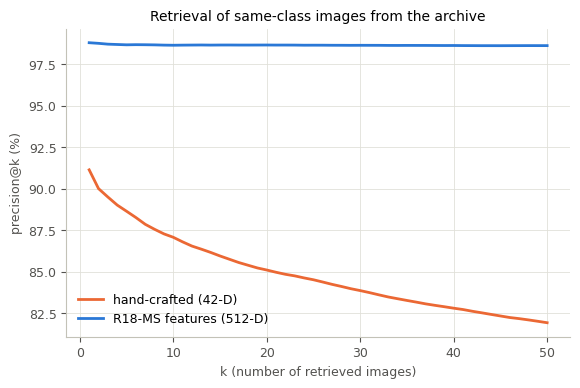

,P@1 (%),P@10 (%),P@50 (%)
hand-crafted (42-D),91.13,87.07,81.93
R18-MS features (512-D),98.78,98.63,98.60


In [36]:
@torch.no_grad()
def retrieve(db, queries, k=50, chunk=1024):
    """Indices of the k most similar archive items (cosine similarity) for every query."""
    db = F.normalize(torch.as_tensor(db, dtype=torch.float32, device=device), dim=1)
    q = F.normalize(torch.as_tensor(queries, dtype=torch.float32, device=device), dim=1)
    return torch.cat([(q[i:i + chunk] @ db.T).topk(k, dim=1).indices for i in range(0, len(q), chunk)]).cpu().numpy()


archive_cnn = predict(models["R18-MS"], tr, main_norm, features=True).cpu().numpy()
descriptors = {"hand-crafted (42-D)": (feature_scaler.transform(F_all[tr]), emb_hand),
               "R18-MS features (512-D)": (archive_cnn, emb_cnn)}
ks = np.arange(1, 51)
precision, ranked = {}, {}
for name, (db, q) in descriptors.items():
    ranked[name] = retrieve(db, q)
    relevant = y_all[tr][ranked[name]] == y_te[:, None]
    precision[name] = 100 * np.cumsum(relevant, axis=1).mean(0) / ks
retrieval = pd.DataFrame({name: p[[0, 9, 49]] for name, p in precision.items()}, index=["P@1 (%)", "P@10 (%)", "P@50 (%)"]).T
retrieval.to_csv(RESULTS_DIR / "retrieval.csv")

fig, ax = plt.subplots(figsize=(6.5, 4))
for (name, p), color in zip(precision.items(), [ORANGE, BLUE]):
    ax.plot(ks, p, color=color, lw=2, label=name)
ax.set_xlabel("k (number of retrieved images)")
ax.set_ylabel("precision@k (%)")
ax.grid(True)
ax.legend()
ax.set_title("Retrieval of same-class images from the archive")
save("retrieval_precision")
retrieval.round(2)

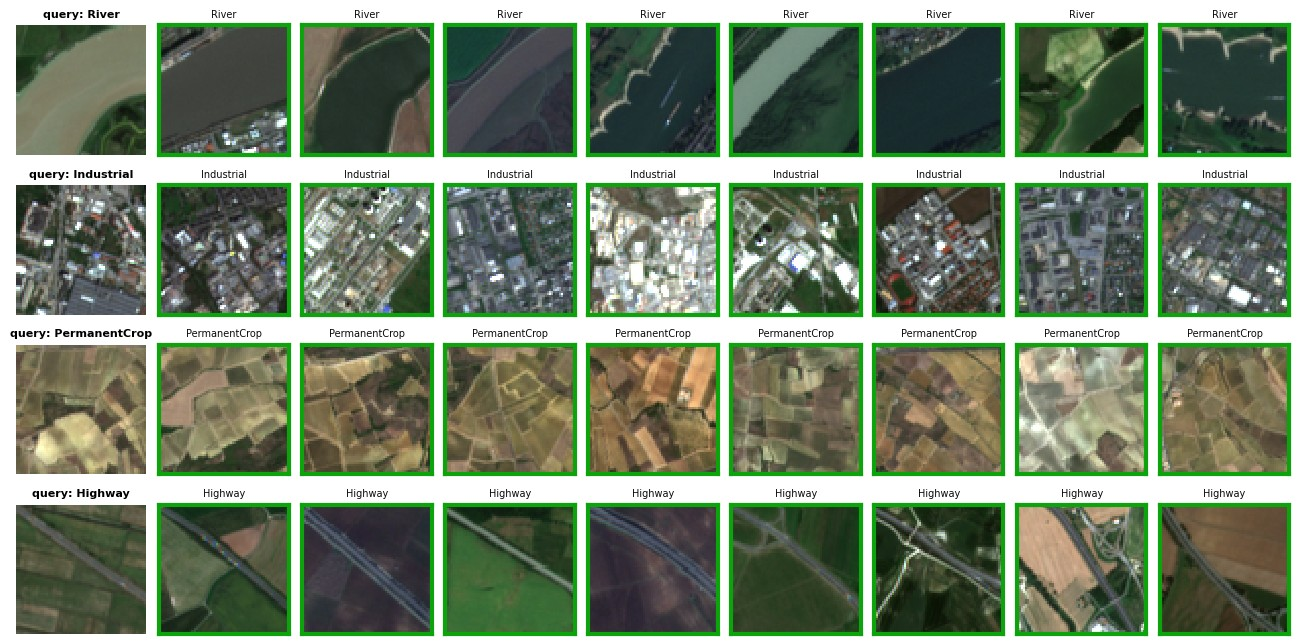

In [37]:
q_rng = np.random.default_rng(SEED)
query_classes = ["River", "Industrial", "PermanentCrop", "Highway"]
queries = [q_rng.choice(np.flatnonzero(y_te == CLASSES.index(c))) for c in query_classes]
fig, axes = plt.subplots(len(queries), 9, figsize=(13, 6.6))
for r, qi in enumerate(queries):
    axes[r, 0].imshow(composite(x_all[te[qi]]))
    no_axes(axes[r, 0])
    axes[r, 0].set_title(f"query: {CLASSES[y_te[qi]]}", fontsize=8, fontweight="bold")
    for j, di in enumerate(ranked["R18-MS features (512-D)"][qi, :8]):
        ax = axes[r, j + 1]
        ax.imshow(composite(x_all[tr[di]]))
        ax.set_xticks([])
        ax.set_yticks([])
        ok = y_all[tr[di]] == y_te[qi]
        for s in ax.spines.values():
            s.set_visible(True)
            s.set_color(GOOD if ok else BAD)
            s.set_linewidth(3)
        ax.set_title(CLASSES[y_all[tr[di]]], fontsize=7, color=INK if ok else BAD)
plt.tight_layout()
save("retrieval_examples", photo=True)

CNN features: precision@10 of 98.6 % vs. 87.1 % with hand-crafted features.

## 12. Generalization to a new region

A random split puts neighbouring, near-identical patches in both training and test sets (spatial autocorrelation). The spatial split tests on an unseen eastern region instead.

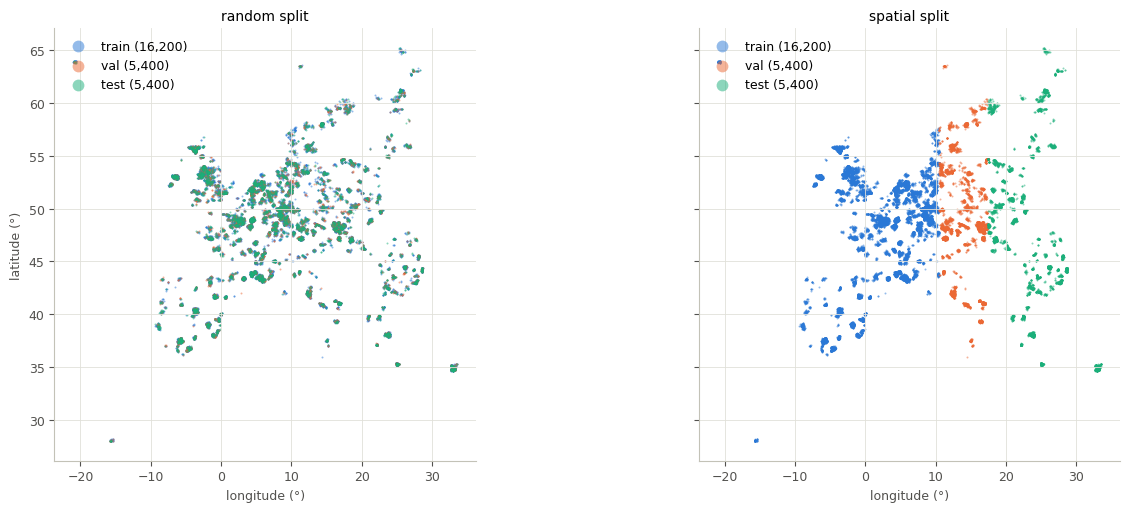

distance from each test patch to the nearest training patch:


,median distance (km),within 1 km (%),within 10 km (%),within 100 km (%)
split,,,,
random,1.2,47.3,97.9,100.0
spatial,1041.0,0.0,0.0,0.0


In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharex=True, sharey=True)
split_color = {"train": BLUE, "val": ORANGE, "test": AQUA}
for ax, protocol in zip(axes, ("random", "spatial")):
    for split, color in split_color.items():
        s = (meta[protocol] == split).values
        ax.scatter(meta.lon[s], meta.lat[s], s=2, color=color, alpha=0.5, linewidths=0, label=f"{split} ({s.sum():,})",
                   rasterized=True)
    ax.set_aspect(1 / np.cos(np.deg2rad(meta.lat.mean())))
    ax.set_title(f"{protocol} split")
    ax.set_xlabel("longitude (°)")
    ax.grid(True)
    ax.legend(markerscale=6, loc="upper left")
axes[0].set_ylabel("latitude (°)")
plt.tight_layout()
save("spatial_split")

rows = []
for protocol in ("random", "spatial"):
    d = cKDTree(xyz[SPLITS[protocol]["train"]]).query(xyz[SPLITS[protocol]["test"]])[0]
    rows.append({"split": protocol, "median distance (km)": np.median(d), "within 1 km (%)": 100 * (d < 1).mean(),
                 "within 10 km (%)": 100 * (d < 10).mean(), "within 100 km (%)": 100 * (d < 100).mean()})
print("distance from each test patch to the nearest training patch:")
pd.DataFrame(rows).set_index("split").round(1)

Both ResNet-18 models are retrained on the spatial split:

In [39]:
for name, bands in (("R18-MS-spatial", ALL_BANDS), ("R18-RGB-spatial", RGB)):
    print(name)
    seed_everything(SEED)
    models[name], histories[name], minutes[name] = train(ResNet18MS(bands), bands, protocol="spatial")
    RUN_BANDS[name] = bands
    torch.save(models[name].state_dict(), CKPT_DIR / f"{name}.pt")
pd.concat(histories, names=["run"]).to_csv(RESULTS_DIR / "training_history.csv")

sp_tr, sp_te = SPLITS["spatial"]["train"], SPLITS["spatial"]["test"]
y_sp = y_all[sp_te]
pred_sp = {"Random forest": RandomForestClassifier(500, n_jobs=-1, random_state=SEED)
           .fit(F_all[sp_tr], y_all[sp_tr]).predict(F_all[sp_te])}
for name in ("R18-RGB", "R18-MS"):
    pred_sp[name] = predict(models[f"{name}-spatial"], sp_te,
                            Standardize("spatial", RUN_BANDS[f"{name}-spatial"])).argmax(1).cpu().numpy()

rows = []
for name in pred_sp:
    r, s = scores(y_te, pred[name]), scores(y_sp, pred_sp[name])
    rows.append({"model": name, "OA random (%)": r["OA (%)"], "OA spatial (%)": s["OA (%)"], "95% CI spatial": s["95% CI"],
                 "macro-F1 random (%)": r["macro-F1 (%)"], "macro-F1 spatial (%)": s["macro-F1 (%)"],
                 "kappa spatial": s["kappa"]})
spatial_results = pd.DataFrame(rows).set_index("model")
spatial_results.insert(3, "OA drop (pp)", spatial_results["OA random (%)"] - spatial_results["OA spatial (%)"])
spatial_results["macro-F1 drop (pp)"] = spatial_results["macro-F1 random (%)"] - spatial_results["macro-F1 spatial (%)"]
spatial_results.to_csv(RESULTS_DIR / "spatial.csv")
only_ms, only_rgb, p = mcnemar(pred_sp["R18-MS"], pred_sp["R18-RGB"], y_sp)
print(f"McNemar, spatial test set, R18-MS vs. R18-RGB: only R18-MS correct {only_ms}, only R18-RGB correct {only_rgb}, p = {p:.2g}")
spatial_results.round(2)

R18-MS-spatial


  epoch  5: train loss 0.602, val loss 0.759, val OA 90.17 %


  epoch 10: train loss 0.545, val loss 0.651, val OA 93.65 %


  epoch 15: train loss 0.518, val loss 0.617, val OA 95.20 %


  epoch 20: train loss 0.509, val loss 0.597, val OA 95.96 %
  -> 3.4 min, best val OA 96.56 % (epoch 17)
R18-RGB-spatial


  epoch  5: train loss 0.597, val loss 0.820, val OA 87.65 %


  epoch 10: train loss 0.552, val loss 0.682, val OA 91.98 %


  epoch 15: train loss 0.521, val loss 0.690, val OA 92.19 %


  epoch 20: train loss 0.511, val loss 0.682, val OA 92.72 %
  -> 3.2 min, best val OA 93.31 % (epoch 14)


McNemar, spatial test set, R18-MS vs. R18-RGB: only R18-MS correct 351, only R18-RGB correct 103, p = 1e-32


,OA random (%),OA spatial (%),95% CI spatial,OA drop (pp),macro-F1 random (%),macro-F1 spatial (%),kappa spatial,macro-F1 drop (pp)
model,,,,,,,,
Random forest,92.43,84.85,83.87 to 85.83,7.57,92.03,80.27,0.83,11.76
R18-RGB,97.74,91.65,90.93 to 92.41,6.09,97.77,90.63,0.90,7.14
R18-MS,98.70,96.24,95.70 to 96.74,2.46,98.67,94.61,0.96,4.06


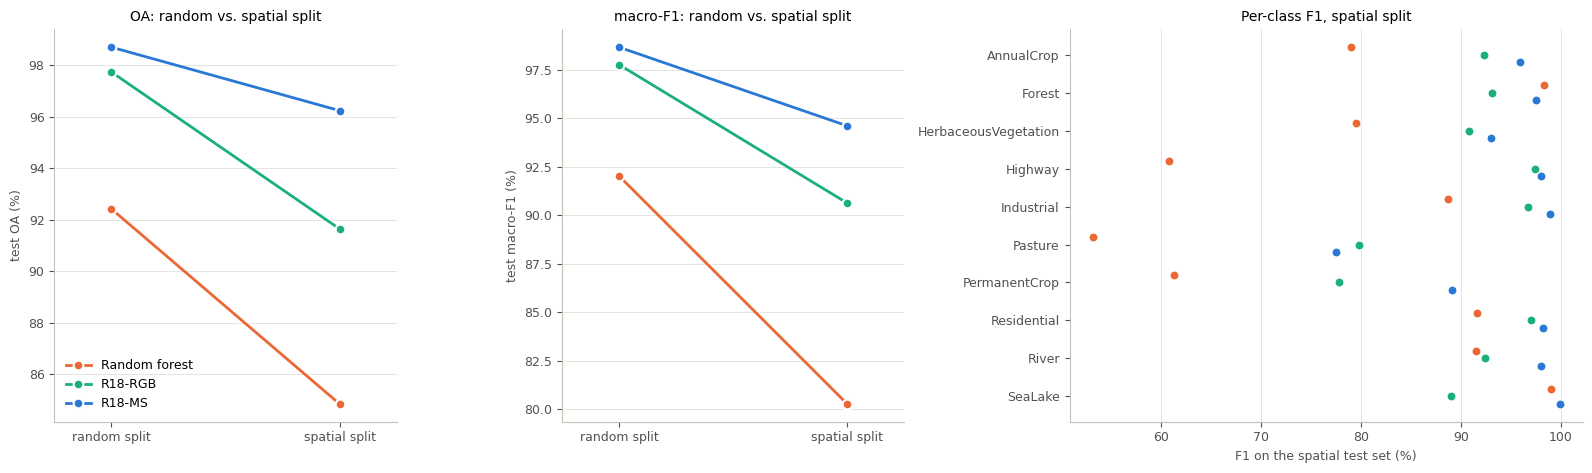

,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River,SeaLake
Random forest,79.0,98.3,79.5,60.8,88.7,53.2,61.3,91.6,91.5,99.0
R18-RGB,92.3,93.1,90.8,97.4,96.7,79.8,77.8,97.0,92.4,88.9
R18-MS,95.9,97.5,93.0,98.0,98.9,77.5,89.1,98.2,98.0,99.9


In [40]:
spatial_colors = {"Random forest": ORANGE, "R18-RGB": AQUA, "R18-MS": BLUE}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1, 1, 1.5]})
for ax, metric in zip(axes[:2], ("OA", "macro-F1")):
    for name, color in spatial_colors.items():
        v = spatial_results.loc[name, [f"{metric} random (%)", f"{metric} spatial (%)"]].values.astype(float)
        ax.plot([0, 1], v, color=color, lw=2, marker="o", ms=7, markeredgecolor="white", markeredgewidth=1.5, label=name)
    ax.set_xticks([0, 1], ["random split", "spatial split"])
    ax.set_xlim(-0.25, 1.25)
    ax.set_ylabel(f"test {metric} (%)")
    ax.grid(True, axis="y")
    ax.set_title(f"{metric}: random vs. spatial split")
axes[0].legend(loc="lower left")
f1_sp = pd.DataFrame({n: 100 * f1_score(y_sp, pred_sp[n], average=None, labels=range(NUM_CLASSES), zero_division=0)
                      for n in spatial_colors}, index=CLASSES)
ax = axes[2]
for k, (name, color) in enumerate(spatial_colors.items()):
    ax.scatter(f1_sp[name], np.arange(NUM_CLASSES) + (k - 1) * 0.2, color=color, s=42, label=name, zorder=3,
               edgecolors="white", linewidths=0.8)
ax.set_yticks(range(NUM_CLASSES), CLASSES)
ax.invert_yaxis()
ax.set_xlabel("F1 on the spatial test set (%)")
ax.grid(True, axis="x")
ax.set_title("Per-class F1, spatial split")
plt.tight_layout()
save("spatial_results")
f1_sp.round(1).T

- Median distance to the nearest training patch: 1.2 km (random) vs. 1,041 km (spatial).
- OA drops: random forest −7.6, RGB −6.1, 13 bands only −2.5 points.
- The 13 bands matter more in the new region (55 % vs. 43 % fewer errors).

## 13. Summary

| model | input | test OA, random split | test OA, spatial split |
|---|---|---|---|
| Gaussian ML (QDA), hand-crafted features | 42 features | 90.83 % | – |
| Random forest, hand-crafted features | 42 features | 92.43 % | 84.85 % |
| RBF-SVM, hand-crafted features | 42 features | 95.31 % | – |
| SpectralSpatialCNN (from scratch) | 13 bands | 95.93 % | – |
| ResNet-18 (random initialization) | 13 bands | 97.91 % | – |
| ResNet-18 (ImageNet) | B04, B03, B02 | 97.74 % | 91.65 % |
| ResNet-18 (ImageNet), no augmentation | 13 bands | 98.57 % | – |
| **ResNet-18 (ImageNet)** | **13 bands** | **98.70 %** (98.80 % with TTA) | **96.24 %** |

- Non-RGB bands: 43 % fewer errors (55 % in a new region).
- CNN > hand-crafted features, mainly on spatial structures (Highway).
- Random splits overestimate the accuracy on a new region.
- Not significant: augmentation, TTA.

**Limitations:** one run per model; the spatial split also includes a regional shift.